In [ ]:

import pandas as pd
import numpy as np
from google.colab import files
from IPython.display import display

# Upload dataset
uploaded = files.upload()

# Load uploaded CSV
filename = next(iter(uploaded))
df = pd.read_csv(filename, low_memory=False)

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Saving loan_book.csv to loan_book.csv
Dataset loaded successfully!
Total Rows: 48355
Total Columns: 40


A2 : Checking on the Duplicates


In [ ]:

# Check whether loan_id is unique
print("Total rows:", len(df))
print("Unique loan IDs:", df["loan_id"].nunique())
print("Duplicate entries:", df["loan_id"].duplicated().sum())

# Extract all rows having duplicate loan IDs
duplicate_loans = df[
    df.duplicated(subset="loan_id", keep=False)
].sort_values("loan_id")

# Display duplicate records
display(duplicate_loans)


Total rows: 48355
Unique loan IDs: 48000
Duplicate entries: 355


,loan_id,customer_id,application_date,disbursal_date,product_type,loan_purpose,sourcing_channel,loan_amount,interest_rate,tenure_months,...,city,state,city_tier,loan_status,days_past_due,total_amount_paid,outstanding_principal,last_payment_date,recovery_amount,collection_agency_assigned
19115,SFL2201100366,C2758665,2022-01-24,2022-01-27,Personal Loan,Home Renovation,Telesales,619000.0,9.50,36,...,Gurugram,Haryana,2,Pre-closed,0,714465.0,0.0,2024-09-30,0.0,No
46664,SFL2201100366,C2758665,2022-01-24,2022-01-27,Personal Loan,Home Renovation,Telesales,619000.0,9.50,36,...,Gurugram,Haryana,2,Pre-closed,0,714465.0,0.0,2024-09-30,0.0,No
9276,SFL2201118023,C7727645,2022-01-28,2022-01-28,Gold Loan,Business Need,Branch,40700.0,10.50,3,...,COIMBATORE,Tamil Nadu,2,Fully Paid,0,41768.0,0.0,2022-05-07,0.0,No
5586,SFL2201118023,C7727645,2022-01-28,2022-01-28,Gold Loan,Business Need,Branch,40700.0,10.50,3,...,Coimbatore,Tamil Nadu,2,Fully Paid,0,41768.0,0.0,2022-05-07,0.0,No
11656,SFL2201132582,C7605494,2022-01-19,2022-01-21,Personal Loan,Other,DSA,302000.0,12.25,24,...,Coimbatore,Tamil Nadu,2,Fully Paid,0,342035.0,0.0,2024-01-22,0.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38073,SFL2507105129,C5805508,2025-06-23,2025-07-05,Personal Loan,Other,Telesales,845000.0,11.70,36,...,Surat,Gujarat,2,Current,0,57080.0,805395.0,2025-09-05,0.0,No
23518,SFL2507137877,C6487907,2025-06-25,2025-07-07,Home Loan,Balance Transfer,DSA,3812000.0,8.25,240,...,BENGALURU,Karnataka,1,Current,0,64980.0,3799410.0,2025-09-05,0.0,No
7187,SFL2507137877,C6487907,2025-06-25,2025-07-07,Home Loan,Balance Transfer,DSA,3812000.0,8.25,240,...,Bengaluru,Karnataka,1,Current,0,64980.0,3799410.0,2025-09-05,0.0,No
33162,SFL2507143027,C5708401,2025-06-27,2025-07-01,Consumer Durable,Laptop,Telesales,57794.0,0.00,9,...,Pune,Maharashtra,1,Current,0,12860.0,44951.0,2025-09-15,0.0,No


In [ ]:

# Remove duplicate rows based on loan_id
df = df.drop_duplicates(subset="loan_id", keep="first").copy()

# Reset index
df.reset_index(drop=True, inplace=True)

# Verify duplicates are removed
print("Total rows after removing duplicates:", df.shape[0])
print("Remaining duplicate loan IDs:", df["loan_id"].duplicated().sum())


Total rows after removing duplicates: 48000
Remaining duplicate loan IDs: 0


In [ ]:
# Display column names and their data types
dtype_summary = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Null Count": df.isna().sum().values
})

display(dtype_summary)

# Additional dataset information
df.info()


,Column Name,Data Type,Non-Null Count,Null Count
0,loan_id,object,48000,0
1,customer_id,object,48000,0
2,application_date,object,48000,0
3,disbursal_date,object,48000,0
4,product_type,object,48000,0
5,loan_purpose,object,48000,0
6,sourcing_channel,object,48000,0
7,loan_amount,float64,48000,0
8,interest_rate,float64,48000,0
9,tenure_months,int64,48000,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 40 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   loan_id                     48000 non-null  object 
 1   customer_id                 48000 non-null  object 
 2   application_date            48000 non-null  object 
 3   disbursal_date              48000 non-null  object 
 4   product_type                48000 non-null  object 
 5   loan_purpose                48000 non-null  object 
 6   sourcing_channel            48000 non-null  object 
 7   loan_amount                 48000 non-null  float64
 8   interest_rate               48000 non-null  float64
 9   tenure_months               48000 non-null  int64  
 10  repayment_type              48000 non-null  object 
 11  emi                         46223 non-null  float64
 12  emi_due_day                 48000 non-null  int64  
 13  processing_fee              480

In [ ]:

# Display all columns without truncation
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)

# Select 30 random records
random_sample = df.sample(n=30)

# Display all columns of the selected records
display(random_sample)


,loan_id,customer_id,application_date,disbursal_date,product_type,loan_purpose,sourcing_channel,loan_amount,interest_rate,tenure_months,repayment_type,emi,emi_due_day,processing_fee,ltv_pct,gold_weight_grams,age,gender,marital_status,education,employment_type,employer_category,years_in_current_job,years_in_business,annual_income,existing_emi,cibil_score,num_existing_loans,num_enquiries_6m,residence_type,city,state,city_tier,loan_status,days_past_due,total_amount_paid,outstanding_principal,last_payment_date,recovery_amount,collection_agency_assigned
28653,SFL2504145189,C1580116,2025-04-05,2025-04-09,Two Wheeler,Two Wheeler Purchase,Branch,106365.0,9.500,36,EMI,3408.0,5,2070.0,NaN,NaN,34,Male,Married,Graduate,Salaried,PSU,0.2,NaN,827000.0,NaN,781,0,0,Rented,Delhi,Delhi,1,Current,0,17040.0,93335.0,2025-09-05,0.0,No
45503,SFL2312121336,C9324392,2023-12-14,2023-12-16,Personal Loan,Other,Digital App,406000.0,13.600,36,EMI,13797.0,2,7510.0,NaN,NaN,32,Male,Married,Graduate,Self-Employed Business,NaN,NaN,5.0,NaN,9600.0,659,1,1,Parental,Kolkata,West Bengal,1,Charged Off,485,55778.0,368586.0,2024-05-05,124071.0,Yes
27320,SFL2402129810,C6928863,2024-01-29,2024-02-05,Personal Loan,Home Renovation,Branch,663000.0,9.500,36,EMI,21238.0,7,8820.0,NaN,NaN,56,Female,Married,12th Pass,Salaried,Startup,25.1,NaN,754000.0,36600.0,799,6,2,Parental,Gurugram,Haryana,2,Current,0,404112.0,336559.0,2025-09-07,0.0,No
34557,SFL2207122137,C4063006,2022-07-21,2022-07-22,Personal Loan,Medical,Digital App,122300.0,13.700,18,EMI,7555.0,5,3350.0,NaN,NaN,28,Male,Single,NaN,Self-Employed Business,NaN,NaN,2.0,175000.0,1200.0,807,5,1,Rented,Nagpur,Maharashtra,2,Fully Paid,0,135991.0,0.0,2024-02-05,0.0,No
22942,SFL2203128469,C4064360,2022-03-28,2022-03-28,Personal Loan,Debt Consolidation,Digital App,223000.0,14.700,48,EMI,6172.0,10,3420.0,NaN,NaN,29,Male,Married,NaN,Self-Employed Professional,NaN,NaN,7.0,357000.0,NaN,706,2,3,Rented,Noida,Uttar Pradesh,2,Current,0,253052.0,41165.0,2025-09-11,0.0,No
46680,SFL2406144073,C7525508,2024-06-13,2024-06-14,Consumer Durable,Television,Fintech Partner,32628.0,0.000,9,EMI,3625.0,2,620.0,NaN,NaN,30,Female,Married,NaN,Self-Employed Business,NaN,NaN,5.0,451000.0,9600.0,727,2,3,Rented,Ahmedabad,Gujarat,1,Fully Paid,0,33953.0,0.0,2025-04-08,0.0,No
8636,SFL2501111974,C4818011,2025-01-08,2025-01-21,Personal Loan,Medical,DSA,289000.0,16.300,48,EMI,8240.0,15,9490.0,NaN,NaN,53,Female,Married,12th Pass,Salaried,Proprietorship,11.2,NaN,408000.0,4700.0,707,1,2,Owned,Meerut,Uttar Pradesh,3,Current,0,67100.0,252842.0,2025-09-15,0.0,No
4653,SFL2312104657,C1665399,2023-12-22,2023-12-22,Consumer Durable,Mobile Phone,Fintech Partner,52916.0,0.000,3,EMI,17639.0,5,1210.0,NaN,NaN,28,Female,Married,Graduate,Salaried,Proprietorship,0.6,NaN,555000.0,8500.0,720,1,3,NaN,Noida,Uttar Pradesh,2,Fully Paid,0,52916.0,0.0,2024-04-05,0.0,No
38322,SFL2210142531,C8458143,06/10/2022,14/10/2022,Business Loan,Machinery,Branch,295000.0,15.800,48,EMI,8331.0,5,8400.0,NaN,NaN,31,Male,Married,Graduate,Self-Employed Business,NaN,NaN,8.0,NaN,6100.0,765,4,2,Parental,Hyderabad,Telangana,1,Current,0,291585.0,98936.0,2025-09-10,0.0,No
8346,SFL2310105135,C4955666,16/10/2023,16/10/2023,Gold Loan,Business Need,Branch,112300.0,12.900,12,Bullet,NaN,5,330.0,68.0,29.2,43,Male,Married,Graduate,Self-Employed Business,NaN,NaN,10.0,612000.0,NaN,781,0,1,Owned,Kanpur,Uttar Pradesh,3,Pre-closed,0,119543.0,0.0,2024-04-30,0.0,No


In [ ]:

# Filter Gold Loans sourced through Branch
filtered_df = df[
    (df["product_type"] == "Gold Loan") &
    (df["sourcing_channel"] == "Branch")
]

print("Total matching rows:", len(filtered_df))

# Display all matching records
display(filtered_df)


Total matching rows: 2491


,loan_id,customer_id,application_date,disbursal_date,product_type,loan_purpose,sourcing_channel,loan_amount,interest_rate,tenure_months,repayment_type,emi,emi_due_day,processing_fee,ltv_pct,gold_weight_grams,age,gender,marital_status,education,employment_type,employer_category,years_in_current_job,years_in_business,annual_income,existing_emi,cibil_score,num_existing_loans,num_enquiries_6m,residence_type,city,state,city_tier,loan_status,days_past_due,total_amount_paid,outstanding_principal,last_payment_date,recovery_amount,collection_agency_assigned
7,SFL2208103961,C2398424,2022-08-16,2022-08-16,Gold Loan,Business Need,Branch,47300.0,15.9,6,Bullet,NaN,5,140.0,62.2,15.5,56,Male,Married,Graduate,Self-Employed Business,NaN,NaN,9.0,NaN,16900.0,674,3,2,Owned,Bhopal,Madhya Pradesh,2,Fully Paid,0,51060.0,0.0,2023-02-11,0.0,No
64,SFL2501106472,C5989251,08/01/2025,08/01/2025,Gold Loan,Agriculture,Branch,369000.0,9.9,9,Monthly Interest,3044.0,7,590.0,57.2,87.5,56,Male,Widowed,Post Graduate,Salaried,Government,6.7,NaN,729000.0,9800.0,701,1,1,Owned,Kanpur,Uttar Pradesh,3,Pre-closed,0,387266.0,0.0,2025-07-10,0.0,No
111,SFL2201114208,C1963640,11/01/2022,11/01/2022,Gold Loan,Other,Branch,161300.0,9.9,6,Bullet,NaN,5,0.0,55.6,64.2,31,Male,Single,Post Graduate,Salaried,Private Ltd,0.8,NaN,564000.0,NaN,739,0,0,Owned,Mumbai,Maharashtra,1,Fully Paid,0,169950.0,0.0,2022-07-30,0.0,No
170,SFL2210125417,C3799788,11/10/2022,11/10/2022,Gold Loan,Agriculture,Branch,139600.0,19.9,6,Bullet,NaN,5,410.0,70.9,39.3,31,Female,Married,Post Graduate,Salaried,Private Ltd,0.1,NaN,858000.0,31900.0,754,1,2,Rented,Mumbai,Maharashtra,1,Fully Paid,0,153490.0,0.0,2023-04-27,0.0,No
199,SFL2409114366,C4447398,2024-09-19,2024-09-19,Gold Loan,Other,Branch,131600.0,14.5,6,Bullet,NaN,7,390.0,67.7,28.3,30,Female,Married,Graduate,Salaried,Government,4.1,NaN,1179000.0,15000.0,761,1,2,Owned,Jaipur,Rajasthan,2,Pre-closed,0,137961.0,0.0,2025-02-08,0.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47948,SFL2308140832,C5821734,2023-08-04,2023-08-04,Gold Loan,Business Need,Branch,185600.0,15.9,6,Bullet,NaN,5,550.0,68.8,48.8,30,Male,Married,Post Graduate,Self-Employed Business,NaN,NaN,2.0,1726000.0,15300.0,732,1,2,Owned,Kolkata,West Bengal,1,Fully Paid,0,201585.0,0.0,2024-02-11,0.0,No
47970,SFL2503114595,C3086412,2025-03-01,2025-03-01,Gold Loan,Business Need,Branch,16400.0,14.5,9,Bullet,NaN,5,0.0,67.8,3.1,41,Male,Married,12th Pass,Salaried,Private Ltd,8.3,NaN,394000.0,NaN,694,0,0,Parental,Ludhiana,Punjab,3,Current,0,0.0,16400.0,NaN,0.0,No
47977,SFL2207109558,C6072160,2022-07-06,2022-07-06,Gold Loan,Business Need,Branch,102500.0,10.0,6,Monthly Interest,854.0,10,300.0,56.1,37.8,33,Female,Married,Post Graduate,Self-Employed Professional,NaN,NaN,5.0,1146000.0,20500.0,752,1,0,Rented,Delhi,Delhi,1,Fully Paid,0,107625.0,0.0,2023-01-25,0.0,No
47978,SFL2304112171,C4197974,26/04/2023,26/04/2023,Gold Loan,Agriculture,Branch,204000.0,10.5,6,Monthly Interest,1785.0,10,590.0,55.2,69.0,32,Male,Married,Professional,Self-Employed Professional,NaN,NaN,4.0,582000.0,4300.0,674,1,3,Parental,Jaipur,Rajasthan,2,Fully Paid,0,215602.0,0.0,2023-11-07,0.0,No


In [ ]:

# Count missing EMI values in filtered Gold Loans (Branch)
emi_nan_count = filtered_df["emi"].isna().sum()

print("Total rows:", len(filtered_df))
print("EMI NaN values:", emi_nan_count)

# Display records where EMI is NaN
display(filtered_df[filtered_df["emi"].isna()])


Total rows: 2491
EMI NaN values: 1094


,loan_id,customer_id,application_date,disbursal_date,product_type,loan_purpose,sourcing_channel,loan_amount,interest_rate,tenure_months,repayment_type,emi,emi_due_day,processing_fee,ltv_pct,gold_weight_grams,age,gender,marital_status,education,employment_type,employer_category,years_in_current_job,years_in_business,annual_income,existing_emi,cibil_score,num_existing_loans,num_enquiries_6m,residence_type,city,state,city_tier,loan_status,days_past_due,total_amount_paid,outstanding_principal,last_payment_date,recovery_amount,collection_agency_assigned
7,SFL2208103961,C2398424,2022-08-16,2022-08-16,Gold Loan,Business Need,Branch,47300.0,15.9,6,Bullet,NaN,5,140.0,62.2,15.5,56,Male,Married,Graduate,Self-Employed Business,NaN,NaN,9.0,NaN,16900.0,674,3,2,Owned,Bhopal,Madhya Pradesh,2,Fully Paid,0,51060.0,0.0,2023-02-11,0.0,No
111,SFL2201114208,C1963640,11/01/2022,11/01/2022,Gold Loan,Other,Branch,161300.0,9.9,6,Bullet,NaN,5,0.0,55.6,64.2,31,Male,Single,Post Graduate,Salaried,Private Ltd,0.8,NaN,564000.0,NaN,739,0,0,Owned,Mumbai,Maharashtra,1,Fully Paid,0,169950.0,0.0,2022-07-30,0.0,No
170,SFL2210125417,C3799788,11/10/2022,11/10/2022,Gold Loan,Agriculture,Branch,139600.0,19.9,6,Bullet,NaN,5,410.0,70.9,39.3,31,Female,Married,Post Graduate,Salaried,Private Ltd,0.1,NaN,858000.0,31900.0,754,1,2,Rented,Mumbai,Maharashtra,1,Fully Paid,0,153490.0,0.0,2023-04-27,0.0,No
199,SFL2409114366,C4447398,2024-09-19,2024-09-19,Gold Loan,Other,Branch,131600.0,14.5,6,Bullet,NaN,7,390.0,67.7,28.3,30,Female,Married,Graduate,Salaried,Government,4.1,NaN,1179000.0,15000.0,761,1,2,Owned,Jaipur,Rajasthan,2,Pre-closed,0,137961.0,0.0,2025-02-08,0.0,No
222,SFL2212104459,C1505719,2022-12-16,2022-12-16,Gold Loan,Business Need,Branch,97300.0,14.5,12,Bullet,NaN,2,0.0,66.6,28.5,33,Female,Married,Post Graduate,Salaried,PSU,0.3,NaN,492000.0,4400.0,882,2,2,Owned,gurgaon,Haryana,2,Pre-closed,0,102003.0,0.0,2023-05-10,0.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47764,SFL2502122752,C5041724,2025-02-07,2025-02-07,Gold Loan,Other,Branch,178300.0,14.0,6,Bullet,NaN,15,530.0,66.5,35.0,38,male,Married,Graduate,Salaried,PSU,0.8,NaN,408000.0,5300.0,694,2,1,Rented,Bengaluru,Karnataka,1,Late (31-90 days),54,0.0,178300.0,NaN,0.0,Yes
47881,SFL2401128015,C9047588,25/01/2024,25/01/2024,Gold Loan,Other,Branch,114900.0,10.5,12,Bullet,NaN,10,340.0,61.7,31.6,26,Male,Single,Graduate,Salaried,Government,3.4,NaN,673000.0,NaN,751,0,2,Parental,Mumbai,Maharashtra,1,Pre-closed,0,124954.0,0.0,2024-12-12,0.0,No
47931,SFL2503108348,C2220194,2025-03-27,2025-03-27,Gold Loan,Business Need,Branch,88300.0,17.9,6,Bullet,NaN,5,260.0,74.5,14.6,37,Female,Married,Graduate,Salaried,Government,1.0,NaN,913000.0,17000.0,766,1,2,Parental,Rohtak,Haryana,3,Pre-closed,0,93569.0,0.0,2025-08-06,0.0,No
47948,SFL2308140832,C5821734,2023-08-04,2023-08-04,Gold Loan,Business Need,Branch,185600.0,15.9,6,Bullet,NaN,5,550.0,68.8,48.8,30,Male,Married,Post Graduate,Self-Employed Business,NaN,NaN,2.0,1726000.0,15300.0,732,1,2,Owned,Kolkata,West Bengal,1,Fully Paid,0,201585.0,0.0,2024-02-11,0.0,No


In [ ]:

# Filter rows with missing education
missing_education = df[df["education"].isna()]

print("Total missing education values:", len(missing_education))

display(missing_education)


Total missing education values: 4595


,loan_id,customer_id,application_date,disbursal_date,product_type,loan_purpose,sourcing_channel,loan_amount,interest_rate,tenure_months,repayment_type,emi,emi_due_day,processing_fee,ltv_pct,gold_weight_grams,age,gender,marital_status,education,employment_type,employer_category,years_in_current_job,years_in_business,annual_income,existing_emi,cibil_score,num_existing_loans,num_enquiries_6m,residence_type,city,state,city_tier,loan_status,days_past_due,total_amount_paid,outstanding_principal,last_payment_date,recovery_amount,collection_agency_assigned
1,SFL2403107971,C6926542,2024-03-11,2024-03-12,Consumer Durable,Laptop,Fintech Partner,39680.0,0.00,3,EMI,13227.0,7,230.0,NaN,NaN,29,Male,Single,NaN,Salaried,Proprietorship,0.6,NaN,NaN,9500.0,595,1,5,Company Provided,Hyderabad,Telangana,1,Fully Paid,0,40535.0,0.0,2024-06-19,0.0,No
13,SFL2205146406,C5622047,2022-05-08,2022-05-08,Gold Loan,Other,Digital App,226000.0,22.00,3,Monthly Interest,4143.0,5,590.0,70.9,67.4,31,Male,Married,NaN,Salaried,Private Ltd,4.3,NaN,511000.0,NaN,737,3,4,Rented,Hyderabad,Telangana,1,Fully Paid,0,238430.0,0.0,2022-08-08,0.0,No
29,SFL2410134601,C6830901,2024-10-23,2024-10-24,Personal Loan,Education,Fintech Partner,388000.0,12.45,48,EMI,10303.0,5,6050.0,NaN,NaN,28,Female,Married,NaN,Salaried,PSU,0.7,NaN,665000.0,17600.0,736,3,1,Parental,Bengaluru,Karnataka,1,Current,0,103030.0,322207.0,2025-09-05,0.0,No
34,SFL2406138549,C5037237,2024-06-25,2024-06-25,Personal Loan,Debt Consolidation,Digital App,470000.0,15.00,18,EMI,29321.0,10,13620.0,NaN,NaN,25,Male,Married,NaN,Self-Employed Business,NaN,NaN,4.0,1504000.0,0.0,-1,0,0,Parental,Bengaluru,Karnataka,1,Current,0,411084.0,113708.0,2025-09-10,0.0,No
44,SFL2306110355,C4621997,2023-06-11,2023-06-13,Consumer Durable,Refrigerator,Fintech Partner,61191.0,0.00,9,EMI,6799.0,15,1680.0,NaN,NaN,34,Male,Married,NaN,Salaried,Government,1.1,NaN,700000.0,30200.0,688,1,5,Owned,Mumbai,Maharashtra,1,Charged Off,777,6799.0,54392.0,2023-07-23,1677.0,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47918,SFL2405105748,C4793207,2024-05-25,2024-05-27,Personal Loan,Other,Digital App,268000.0,15.10,60,EMI,6390.0,15,8530.0,NaN,NaN,35,Male,Single,NaN,Salaried,Government,10.4,NaN,620000.0,23900.0,740,1,1,Owned,Gurugram,Haryana,2,Current,0,95850.0,218526.0,2025-09-15,0.0,No
47932,SFL2401112889,C8142680,2024-01-01,2024-01-09,Personal Loan,Debt Consolidation,Telesales,471000.0,14.75,12,EMI,42460.0,5,6950.0,NaN,NaN,28,Male,Married,NaN,Self-Employed Business,NaN,NaN,6.0,741000.0,13600.0,681,1,1,Parental,Hyderabad,Telangana,1,Pre-closed,0,501998.0,0.0,2024-04-19,0.0,No
47956,SFL2409139139,C4885536,2024-09-02,2024-09-03,Personal Loan,Medical,Fintech Partner,413000.0,15.25,24,EMI,20074.0,10,5620.0,NaN,NaN,24,F,Single,NaN,Salaried,MNC,0.5,NaN,1321000.0,0.0,-1,0,4,NaN,Noida,Uttar Pradesh,2,Current,0,242068.0,222117.0,2025-09-24,0.0,No
47976,SFL2202147084,C6302716,2022-02-16,2022-02-18,Personal Loan,Education,Digital App,182400.0,11.75,36,EMI,6037.0,5,2690.0,NaN,NaN,39,Male,Married,NaN,Salaried,Private Ltd,5.4,NaN,314000.0,NaN,843,0,1,Owned,Guwahati,Assam,3,Fully Paid,0,217315.0,0.0,2025-03-06,0.0,No


In [ ]:

# Filter rows where employer_category is NaN
missing_employer = df[df["employer_category"].isna()]

print("Total missing employer_category values:", len(missing_employer))

# Display relevant columns
display(missing_employer[
    ["employment_type", "sourcing_channel", "city_tier", "employer_category"]
])


Total missing employer_category values: 19671


,employment_type,sourcing_channel,city_tier,employer_category
2,Self-Employed Professional,Branch,1,NaN
3,Self-Employed Business,DSA,2,NaN
7,Self-Employed Business,Branch,2,NaN
8,Self-Employed Professional,Branch,1,NaN
9,Self-Employed Business,Branch,1,NaN
...,...,...,...,...
47986,Self-Employed Business,DSA,3,NaN
47989,Self-Employed Business,Digital App,1,NaN
47990,Salaried,Fintech Partner,1,NaN
47993,Self-Employed Business,Branch,1,NaN


In [ ]:

columns_to_check = [
    "employment_type",
    "sourcing_channel",
    "city_tier"
]

for col in columns_to_check:
    print(f"\n--- Missing Employer Category by {col} ---")

    summary = df.groupby(col, dropna=False)["employer_category"].agg(
        Total="size",
        Missing=lambda x: x.isna().sum(),
        Missing_Percentage=lambda x: round(x.isna().mean() * 100, 2)
    )

    display(summary.sort_values(
        "Missing_Percentage",
        ascending=False
    ))



--- Missing Employer Category by employment_type ---


,Total,Missing,Missing_Percentage
employment_type,,,
SELF-EMPLOYED BUSINESS,8,8,100.00
SELF-EMPLOYED BUSINESS,304,304,100.00
SELF-EMPLOYED PROFESSIONAL,2,2,100.00
SELF-EMPLOYED PROFESSIONAL,130,130,100.00
Self-Employed Professional,5747,5747,100.00
Self-Employed Professional,120,120,100.00
Self-Employed Business,235,235,100.00
Self-Employed Business,11945,11945,100.00
SALARIED,16,1,6.25



--- Missing Employer Category by sourcing_channel ---


,Total,Missing,Missing_Percentage
sourcing_channel,,,
Fintech Partner,7421,3098,41.75
DSA,10713,4424,41.30
Telesales,3976,1636,41.15
Digital App,10757,4397,40.88
Branch,15133,6116,40.41



--- Missing Employer Category by city_tier ---


,Total,Missing,Missing_Percentage
city_tier,,,
1,25093,10315,41.11
2,15778,6445,40.85
3,7129,2911,40.83


In [ ]:

# Filter rows where years_in_current_job is NaN
missing_job_years = df[df["years_in_current_job"].isna()]

print("Total missing years_in_current_job values:", len(missing_job_years))

display(missing_job_years[
    ["employment_type", "sourcing_channel",
     "city_tier", "years_in_current_job"]
])


Total missing years_in_current_job values: 18491


,employment_type,sourcing_channel,city_tier,years_in_current_job
2,Self-Employed Professional,Branch,1,NaN
3,Self-Employed Business,DSA,2,NaN
7,Self-Employed Business,Branch,2,NaN
8,Self-Employed Professional,Branch,1,NaN
9,Self-Employed Business,Branch,1,NaN
...,...,...,...,...
47985,Self-Employed Business,Digital App,1,NaN
47986,Self-Employed Business,DSA,3,NaN
47989,Self-Employed Business,Digital App,1,NaN
47993,Self-Employed Business,Branch,1,NaN


In [ ]:

columns_to_check = [
    "employment_type",
    "sourcing_channel",
    "city_tier"
]

for col in columns_to_check:
    print(f"\n--- Missing Years in Current Job by {col} ---")

    summary = df.groupby(col, dropna=False)["years_in_current_job"].agg(
        Total="size",
        Missing=lambda x: x.isna().sum(),
        Missing_Percentage=lambda x: round(x.isna().mean() * 100, 2)
    )

    display(summary.sort_values(
        "Missing_Percentage",
        ascending=False
    ))



--- Missing Years in Current Job by employment_type ---


,Total,Missing,Missing_Percentage
employment_type,,,
SELF-EMPLOYED BUSINESS,8,8,100.0
SELF-EMPLOYED BUSINESS,304,304,100.0
SELF-EMPLOYED PROFESSIONAL,2,2,100.0
SELF-EMPLOYED PROFESSIONAL,130,130,100.0
Self-Employed Professional,5747,5747,100.0
Self-Employed Professional,120,120,100.0
Self-Employed Business,235,235,100.0
Self-Employed Business,11945,11945,100.0
SALARIED,611,0,0.0



--- Missing Years in Current Job by sourcing_channel ---


,Total,Missing,Missing_Percentage
sourcing_channel,,,
Fintech Partner,7421,2905,39.15
Telesales,3976,1541,38.76
DSA,10713,4142,38.66
Digital App,10757,4136,38.45
Branch,15133,5767,38.11



--- Missing Years in Current Job by city_tier ---


,Total,Missing,Missing_Percentage
city_tier,,,
2,15778,6090,38.60
1,25093,9665,38.52
3,7129,2736,38.38


In [ ]:


missing_business_years = df[df["years_in_business"].isna()]

print("Total missing years_in_business values:", len(missing_business_years))

display(missing_job_years[
    ["employment_type", "sourcing_channel",
     "city_tier", "years_in_business"]
])



Total missing years_in_business values: 29509


,employment_type,sourcing_channel,city_tier,years_in_business
2,Self-Employed Professional,Branch,1,9.0
3,Self-Employed Business,DSA,2,5.0
7,Self-Employed Business,Branch,2,9.0
8,Self-Employed Professional,Branch,1,4.0
9,Self-Employed Business,Branch,1,2.0
...,...,...,...,...
47985,Self-Employed Business,Digital App,1,8.0
47986,Self-Employed Business,DSA,3,3.0
47989,Self-Employed Business,Digital App,1,8.0
47993,Self-Employed Business,Branch,1,1.0


In [ ]:

columns_to_check = [
    "employment_type",
    "sourcing_channel",
    "city_tier"
]

for col in columns_to_check:
    print(f"\n--- Missing Years in Current buisness year by {col} ---")

    summary = df.groupby(col, dropna=False)["years_in_business"].agg(
        Total="size",
        Missing=lambda x: x.isna().sum(),
        Missing_Percentage=lambda x: round(x.isna().mean() * 100, 2)
    )

    display(summary.sort_values(
        "Missing_Percentage",
        ascending=False
    ))



--- Missing Years in Current buisness year by employment_type ---


,Total,Missing,Missing_Percentage
employment_type,,,
SALARIED,611,611,100.0
SALARIED,16,16,100.0
Salaried,28303,28303,100.0
Salaried,579,579,100.0
SELF-EMPLOYED BUSINESS,8,0,0.0
SELF-EMPLOYED BUSINESS,304,0,0.0
SELF-EMPLOYED PROFESSIONAL,2,0,0.0
SELF-EMPLOYED PROFESSIONAL,130,0,0.0
Self-Employed Business,11945,0,0.0



--- Missing Years in Current buisness year by sourcing_channel ---


,Total,Missing,Missing_Percentage
sourcing_channel,,,
Branch,15133,9366,61.89
Digital App,10757,6621,61.55
DSA,10713,6571,61.34
Telesales,3976,2435,61.24
Fintech Partner,7421,4516,60.85



--- Missing Years in Current buisness year by city_tier ---


,Total,Missing,Missing_Percentage
city_tier,,,
3,7129,4393,61.62
1,25093,15428,61.48
2,15778,9688,61.40


In [ ]:

# Filter rows where annual_income is NaN
missing_income = df[df["annual_income"].isna()]

print("Total missing annual_income values:", len(missing_income))

display(missing_income[
    ["employment_type", "sourcing_channel",
     "city_tier", "num_existing_loans", "annual_income"]
])


Total missing annual_income values: 3770


,employment_type,sourcing_channel,city_tier,num_existing_loans,annual_income
1,Salaried,Fintech Partner,1,1,NaN
7,Self-Employed Business,Branch,2,3,NaN
40,Self-Employed Business,Digital App,3,1,NaN
74,Self-Employed Professional,DSA,2,1,NaN
84,SELF-EMPLOYED PROFESSIONAL,DSA,2,1,NaN
...,...,...,...,...,...
47929,Self-Employed Professional,Digital App,1,0,NaN
47941,Self-Employed Business,DSA,1,3,NaN
47947,Self-Employed Business,Branch,2,2,NaN
47965,Self-Employed Professional,Digital App,1,2,NaN


In [ ]:

columns_to_check = [
    "employment_type",
    "sourcing_channel",
    "city_tier",
    "num_existing_loans"
]

for col in columns_to_check:
    print(f"\n--- Missing Annual Income by {col} ---")

    summary = df.groupby(col, dropna=False)["annual_income"].agg(
        Total="size",
        Missing=lambda x: x.isna().sum(),
        Missing_Percentage=lambda x: round(x.isna().mean() * 100, 2)
    )

    display(summary.sort_values(
        "Missing_Percentage",
        ascending=False
    ))



--- Missing Annual Income by employment_type ---


,Total,Missing,Missing_Percentage
employment_type,,,
SELF-EMPLOYED BUSINESS,8,2,25.00
SELF-EMPLOYED PROFESSIONAL,130,26,20.00
Self-Employed Professional,5747,1064,18.51
Self-Employed Business,11945,2129,17.82
SELF-EMPLOYED BUSINESS,304,51,16.78
Self-Employed Business,235,39,16.60
Self-Employed Professional,120,17,14.17
SALARIED,16,1,6.25
SALARIED,611,11,1.80



--- Missing Annual Income by sourcing_channel ---


,Total,Missing,Missing_Percentage
sourcing_channel,,,
Telesales,3976,331,8.32
Fintech Partner,7421,602,8.11
Branch,15133,1198,7.92
DSA,10713,830,7.75
Digital App,10757,809,7.52



--- Missing Annual Income by city_tier ---


,Total,Missing,Missing_Percentage
city_tier,,,
1,25093,2008,8.00
2,15778,1223,7.75
3,7129,539,7.56



--- Missing Annual Income by num_existing_loans ---


,Total,Missing,Missing_Percentage
num_existing_loans,,,
7,88,9,10.23
8,20,2,10.00
5,952,82,8.61
4,2727,224,8.21
1,14260,1154,8.09
2,11088,876,7.90
0,12296,951,7.73
3,6300,457,7.25
6,264,15,5.68


The Emi for Gold loan taken at branch is mostly Nan like from all the 1777 values in the emi nan values at the gold branch are 1094 which means mostly they came from this.

lvt_pct : it is only for Home , Gold Loans.

gold_per_gram : it only applies to gold

Education : it has 4595 missing nan values but it is mostly due to data inconsistency or due to not mandatory column for the loan giving.

Employer Category years_in_current_job : is missing or has nan values for self_buisness , self_employed maximumly

CurrentJobYears : only salaried guys are missing that data which is reasonable.

existing emi : may be the data is not present for it it showed no clear patterns on nan.

annual income : self employed business and professionals have large distribution of nan value in annual income rest have less.





# B will check into this

In [ ]:

# Convert both columns to datetime (handles mixed date formats)
for col in ["application_date", "disbursal_date"]:
    df[col] = pd.to_datetime(
        df[col],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

# Display dates in DD-MM-YYYY format
for col in ["application_date", "disbursal_date"]:
    print(f"\n{col}")
    print(df[col].dt.strftime("%d-%m-%Y").head(10))

# Check data types
print(df[["application_date", "disbursal_date"]].dtypes)

# Check dates that could not be parsed
print("\nInvalid dates:")
print(df[["application_date", "disbursal_date"]].isna().sum())



application_date
0    12-07-2023
1    11-03-2024
2    01-03-2025
3    15-05-2024
4    27-03-2025
5    25-11-2023
6    24-12-2022
7    16-08-2022
8    30-08-2023
9    12-04-2024
Name: application_date, dtype: object

disbursal_date
0    24-07-2023
1    12-03-2024
2    07-03-2025
3    20-05-2024
4    27-03-2025
5    27-11-2023
6    07-01-2023
7    16-08-2022
8    07-09-2023
9    22-04-2024
Name: disbursal_date, dtype: object
application_date    datetime64[ns]
disbursal_date      datetime64[ns]
dtype: object

Invalid dates:
application_date    0
disbursal_date      0
dtype: int64


In [ ]:
print(df)



             loan_id customer_id application_date disbursal_date      product_type          loan_purpose sourcing_channel  loan_amount  interest_rate  tenure_months repayment_type      emi  emi_due_day  processing_fee  ltv_pct  gold_weight_grams  age  gender marital_status      education              employment_type employer_category  years_in_current_job  years_in_business annual_income  existing_emi  cibil_score  num_existing_loans  num_enquiries_6m    residence_type       city        state  city_tier loan_status  days_past_due  total_amount_paid  outstanding_principal last_payment_date  recovery_amount collection_agency_assigned
0      SFL2307124379    C2637213       2023-07-12     2023-07-24     Personal Loan                 Other           Branch     162600.0          11.25             12            EMI  14390.0            5          2750.0      NaN                NaN   37  Female        Married      12th Pass                     Salaried       Private Ltd                   1.5   

In [ ]:

# List of categorical columns
categorical_columns = [
    "product_type",
    "loan_purpose",
    "sourcing_channel",
    "repayment_type",
    "gender",
    "marital_status",
    "education",
    "employment_type",
    "employer_category",
    "residence_type",
    "city",
    "state"
]

# Display unique values and their frequencies
for col in categorical_columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print(f"Number of unique values: {df[col].nunique(dropna=False)}")
    print(f"{'='*50}")

    display(df[col].value_counts(dropna=False).to_frame("Count"))



Column: product_type
Number of unique values: 9


,Count
product_type,
Personal Loan,24701
Consumer Durable,10521
Gold Loan,4006
Home Loan,3013
Two Wheeler,2845
Business Loan,2151
PL,262
personal_loan,252
Personal loan,249



Column: loan_purpose
Number of unique values: 23


,Count
loan_purpose,
Debt Consolidation,5598
Other,4594
Wedding,4477
Home Renovation,3840
Mobile Phone,3812
Medical,3711
Two Wheeler Purchase,2845
Travel,2594
Education,2444



Column: sourcing_channel
Number of unique values: 5


,Count
sourcing_channel,
Branch,15133
Digital App,10757
DSA,10713
Fintech Partner,7421
Telesales,3976


... (14 outputs left out)


Column: city
Number of unique values: 72


,Count
city,
Bengaluru,3543
Mumbai,3513
Delhi,3444
Pune,2810
Chennai,2377
...,...
PANIPAT,1
DELHI,1
VARANASI,1



Column: state
Number of unique values: 19


,Count
state,
Maharashtra,8449
Uttar Pradesh,5773
Karnataka,4591
Delhi,4005
Gujarat,3744
Tamil Nadu,3703
Haryana,2980
Telangana,2706
Madhya Pradesh,2304


In [ ]:

# 1. Standardize product_type
df["product_type"] = (
    df["product_type"]
    .str.strip()
    .str.lower()
    .str.replace("_", " ", regex=False)
    .replace({
        "pl": "personal loan"
    })
    .str.title()
)

# 2. Standardize gender
df["gender"] = (
    df["gender"]
    .str.strip()
    .str.lower()
    .replace({
        "m": "male",
        "f": "female"
    })
    .str.title()
)

# 3. Standardize employment_type
df["employment_type"] = (
    df["employment_type"]
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

# Verify unique values after cleaning
for col in ["product_type", "gender", "employment_type"]:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False))



--- product_type ---


,count
product_type,
Personal Loan,25464
Consumer Durable,10521
Gold Loan,4006
Home Loan,3013
Two Wheeler,2845
Business Loan,2151



--- gender ---


,count
gender,
Male,35163
Female,12837



--- employment_type ---


,count
employment_type,
Salaried,29509
Self-Employed Business,12492
Self-Employed Professional,5999


In [ ]:

# Display every unique city with its frequency
city_counts = (
    df["city"]
    .value_counts(dropna=False)
    .reset_index()
)

city_counts.columns = ["City", "Count"]

print("Total unique city values:",
      df["city"].nunique(dropna=False))

# Prevent output truncation
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    print(city_counts.to_string(index=False))


Total unique city values: 72
      City  Count
 Bengaluru   3543
    Mumbai   3513
     Delhi   3444
      Pune   2810
   Chennai   2377
 Ahmedabad   2326
 Hyderabad   2325
   Kolkata   1951
    Jaipur   1903
     Noida   1877
   Lucknow   1832
  Gurugram   1586
     Surat   1415
    Indore   1412
Coimbatore    939
     Kochi    939
    Kanpur    935
     Patna    922
    Nagpur    905
    Bhopal    889
Chandigarh    887
   Panipat    729
  Ludhiana    716
    Meerut    692
Vijayawada    662
    Nashik    646
    Ranchi    481
  Guwahati    479
    Raipur    477
    Mysuru    468
  Varanasi    433
    Rohtak    405
  Calcutta    316
   Mumbai     205
Hyderabad     198
   chennai    197
    mumbai    193
 NEW DELHI    191
    Madras    189
 New Delhi    185
     delhi    184
 hyderabad    180
    Bombay    172
 BANGALORE    156
 Bangalore    148
 bengaluru    143
   Gurgaon    135
Bengaluru     129
   gurgaon    123
 BENGALURU      3
    MUMBAI      3
 AHMEDABAD      3
 HYDERABAD      3

In [ ]:

# Step 1: Remove extra spaces and standardize capitalization
df["city"] = df["city"].str.strip().str.title()

# Step 2: Merge different names referring to the same city
city_mapping = {
    "Bangalore": "Bengaluru",
    "Bombay": "Mumbai",
    "Madras": "Chennai",
    "Calcutta": "Kolkata",
    "New Delhi": "Delhi",
    "Gurgaon": "Gurugram"
}

df["city"] = df["city"].replace(city_mapping)

# Step 3: Verify cleaned city names and counts
print("Total unique cities after cleaning:", df["city"].nunique())

print("\nCity-wise counts after cleaning:")
display(df["city"].value_counts(dropna=False))

# Step 4: Check for remaining variations
print("\nAll unique city names:")
print(sorted(df["city"].dropna().unique()))


Total unique cities after cleaning: 32

City-wise counts after cleaning:


,count
city,
Bengaluru,4122
Mumbai,4087
Delhi,4005
Pune,2811
Chennai,2763
Hyderabad,2706
Ahmedabad,2329
Kolkata,2270
Jaipur,1905



All unique city names:
['Ahmedabad', 'Bengaluru', 'Bhopal', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Indore', 'Jaipur', 'Kanpur', 'Kochi', 'Kolkata', 'Lucknow', 'Ludhiana', 'Meerut', 'Mumbai', 'Mysuru', 'Nagpur', 'Nashik', 'Noida', 'Panipat', 'Patna', 'Pune', 'Raipur', 'Ranchi', 'Rohtak', 'Surat', 'Varanasi', 'Vijayawada']


In [ ]:
print(df)

             loan_id customer_id application_date disbursal_date      product_type          loan_purpose sourcing_channel  loan_amount  interest_rate  tenure_months repayment_type      emi  emi_due_day  processing_fee  ltv_pct  gold_weight_grams  age  gender marital_status      education             employment_type employer_category  years_in_current_job  years_in_business annual_income  existing_emi  cibil_score  num_existing_loans  num_enquiries_6m    residence_type       city        state  city_tier loan_status  days_past_due  total_amount_paid  outstanding_principal last_payment_date  recovery_amount collection_agency_assigned
0      SFL2307124379    C2637213       2023-07-12     2023-07-24     Personal Loan                 Other           Branch     162600.0          11.25             12            EMI  14390.0            5          2750.0      NaN                NaN   37  Female        Married      12th Pass                    Salaried       Private Ltd                   1.5     

In [ ]:

# Store original values for comparison
original_dates = df["last_payment_date"].copy()

# Convert mixed date formats to datetime
df["last_payment_date"] = pd.to_datetime(
    df["last_payment_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Check values before and after conversion
comparison = pd.DataFrame({
    "Before": original_dates,
    "After": df["last_payment_date"].dt.strftime("%d-%m-%Y")
})

display(comparison.sample(n=30, random_state=42))

# Verify data type and missing values
print("Data type:", df["last_payment_date"].dtype)
print("Missing values before:", original_dates.isna().sum())
print("Missing values after:", df["last_payment_date"].isna().sum())

# Check any non-missing values that failed conversion
failed = original_dates.notna() & df["last_payment_date"].isna()
print("Failed conversions:", failed.sum())
display(comparison[failed])


,Before,After
32771,2025-09-07,07-09-2025
39512,2024-04-11,11-04-2024
43581,2025-09-07,07-09-2025
2975,2023-08-11,11-08-2023
3377,2025-09-07,07-09-2025
3792,2024-04-05,05-04-2024
34123,2024-12-01,01-12-2024
19847,2025-04-02,02-04-2025
10421,2025-01-18,18-01-2025
28533,2023-09-17,17-09-2023


Data type: datetime64[ns]
Missing values before: 533
Missing values after: 533
Failed conversions: 0


,Before,After


In [ ]:

# Columns to convert into float64
numeric_columns = [
    "loan_amount",
    "emi",
    "processing_fee",
    "annual_income",
    "existing_emi",
    "total_amount_paid",
    "outstanding_principal"
]

# Store original values for comparison
original_values = df[numeric_columns].copy()

# Convert to numeric and standardize as float64
for col in numeric_columns:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.replace(",", "", regex=False)
        .str.replace("₹", "", regex=False)
    )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    ).astype("float64")

# Verify data types
print("Data types after conversion:")
print(df[numeric_columns].dtypes)

# Check if any new NaN values were introduced
print("\nNew missing values after conversion:")

for col in numeric_columns:
    new_nan = df[col].isna().sum() - original_values[col].isna().sum()
    print(f"{col}: {new_nan}")

# Display 30 random records
display(df[numeric_columns].sample(30, random_state=42))


Data types after conversion:
loan_amount              float64
emi                      float64
processing_fee           float64
annual_income            float64
existing_emi             float64
total_amount_paid        float64
outstanding_principal    float64
dtype: object

New missing values after conversion:
loan_amount: 0
emi: 0
processing_fee: 0
annual_income: 413
existing_emi: 0
total_amount_paid: 0
outstanding_principal: 0


,loan_amount,emi,processing_fee,annual_income,existing_emi,total_amount_paid,outstanding_principal
32771,1311000.0,44807.0,43150.0,1245000.0,18600.0,492877.0,966754.0
39512,61680.0,10280.0,2040.0,685000.0,5400.0,61680.0,0.0
43581,234000.0,7856.0,4810.0,229000.0,3000.0,15712.0,223203.0
2975,414000.0,14792.0,11110.0,NaN,31200.0,474222.0,0.0
3377,294000.0,10257.0,7790.0,593000.0,9100.0,174959.0,171894.0
3792,1571000.0,97195.0,54470.0,1718000.0,0.0,97195.0,1492002.0
34123,991000.0,91351.0,22380.0,1240000.0,0.0,140814.0,915381.0
19847,32854.0,3650.0,1180.0,362000.0,12200.0,32854.0,0.0
10421,524000.0,32875.0,15150.0,933000.0,28900.0,32875.0,498003.0
28533,667000.0,59388.0,8580.0,652000.0,7000.0,714422.0,0.0


B2

In [ ]:

# Dictionary to store validation checks
checks = {
    "1. Age below 18 or above 100":
        (df["age"] < 18) | (df["age"] > 100),

    "2. Disbursal before application":
        df["disbursal_date"] < df["application_date"],

    "3. Loan amount <= 0":
        df["loan_amount"] <= 0,

    "4. Interest rate below 0 or above 60%":
        (df["interest_rate"] < 0) | (df["interest_rate"] > 60),

    "5. Loan tenure <= 0":
        df["tenure_months"] <= 0,

    "6. Negative EMI":
        df["emi"] < 0,

    "7. Negative annual income":
        df["annual_income"] < 0,

    "8. CIBIL score outside valid range":
        ~(
            df["cibil_score"].between(300, 900) |
            (df["cibil_score"] == -1)
        ),

    "9. Negative existing EMI":
        df["existing_emi"] < 0,

    "10. Negative outstanding principal":
        df["outstanding_principal"] < 0,

    "11. Invalid EMI due day":
        ~df["emi_due_day"].between(1, 31),

    "12. Invalid LTV percentage":
        (df["ltv_pct"] < 0) | (df["ltv_pct"] > 100)
}

# Create summary of failed checks
quality_report = pd.DataFrame({
    "Validation Check": list(checks.keys()),
    "Rows Failed": [
        condition.sum() for condition in checks.values()
    ]
})

display(quality_report)


,Validation Check,Rows Failed
0,1. Age below 18 or above 100,31
1,2. Disbursal before application,60
2,3. Loan amount <= 0,0
3,4. Interest rate below 0 or above 60%,0
4,5. Loan tenure <= 0,8
5,6. Negative EMI,0
6,7. Negative annual income,19
7,8. CIBIL score outside valid range,52
8,9. Negative existing EMI,0
9,10. Negative outstanding principal,0


In [ ]:

# Set invalid ages to NaN (assumed plausible range: 18-100)
df.loc[
    (df["age"] < 18) | (df["age"] > 100),
    "age"
] = np.nan

# Set invalid loan tenure to NaN
df.loc[
    df["tenure_months"] <= 0,
    "tenure_months"
] = np.nan

# Set negative annual income to NaN
df.loc[
    df["annual_income"] < 0,
    "annual_income"
] = np.nan

# Set invalid CIBIL scores to NaN
df.loc[
    ~(
        df["cibil_score"].between(300, 900) |
        (df["cibil_score"] == -1)
    ),
    "cibil_score"
] = np.nan

print("Invalid numerical values replaced with NaN.")


Invalid numerical values replaced with NaN.


In [ ]:

invalid_dates = df[
    df["disbursal_date"] < df["application_date"]
].copy()

invalid_dates["days_difference"] = (
    invalid_dates["disbursal_date"] -
    invalid_dates["application_date"]
).dt.days

print("Total invalid date records:", len(invalid_dates))

display(
    invalid_dates[
        [
            "loan_id",
            "application_date",
            "disbursal_date",
            "days_difference",
            "product_type",
            "sourcing_channel"
        ]
    ].sort_values("days_difference")
)


Total invalid date records: 60


,loan_id,application_date,disbursal_date,days_difference,product_type,sourcing_channel
38553,SFL2401126209,2024-01-31,2023-12-19,-43,Home Loan,Branch
10103,SFL2211103502,2022-11-25,2022-11-11,-14,Personal Loan,Branch
21911,SFL2409140516,2024-09-02,2024-08-19,-14,Consumer Durable,Branch
22762,SFL2206141221,2022-06-06,2022-05-23,-14,Personal Loan,Telesales
35841,SFL2407116244,2024-07-18,2024-07-04,-14,Personal Loan,Branch
43828,SFL2402108771,2024-02-12,2024-01-29,-14,Personal Loan,DSA
31683,SFL2203131421,2022-03-21,2022-03-07,-14,Two Wheeler,Branch
7536,SFL2202106538,2022-02-07,2022-01-25,-13,Business Loan,Branch
9448,SFL2210121581,2022-10-13,2022-09-30,-13,Two Wheeler,DSA
24141,SFL2305140675,2023-05-22,2023-05-09,-13,Consumer Durable,DSA


In [ ]:

# Store original row count
rows_before = len(df)

# Identify invalid date sequences
invalid_mask = (
    df["disbursal_date"] < df["application_date"]
)

print("Invalid records found:", invalid_mask.sum())

# Remove invalid records
df = df.loc[~invalid_mask].copy()

# Reset index
df.reset_index(drop=True, inplace=True)

# Verify cleaning
print("Rows before:", rows_before)
print("Rows removed:", rows_before - len(df))
print("Rows remaining:", len(df))

print(
    "Remaining invalid date sequences:",
    (df["disbursal_date"] < df["application_date"]).sum()
)


Invalid records found: 60
Rows before: 48000
Rows removed: 60
Rows remaining: 47940
Remaining invalid date sequences: 0


In [ ]:

# Select only EMI repayment loans
emi_df = df[
    df["repayment_type"].str.strip().str.upper() == "EMI"
].copy()

# Monthly interest rate
emi_df["monthly_rate"] = emi_df["interest_rate"] / (12 * 100)

# Calculate EMI only where required inputs are valid
valid = (
    emi_df["loan_amount"].gt(0) &
    emi_df["tenure_months"].gt(0) &
    emi_df["interest_rate"].ge(0) &
    emi_df[["loan_amount", "interest_rate", "tenure_months"]]
    .notna().all(axis=1)
)

emi_df["calculated_emi"] = np.nan

# Zero-interest loans
zero_rate = valid & emi_df["monthly_rate"].eq(0)

emi_df.loc[zero_rate, "calculated_emi"] = (
    emi_df.loc[zero_rate, "loan_amount"] /
    emi_df.loc[zero_rate, "tenure_months"]
)

# Positive-interest loans
positive_rate = valid & emi_df["monthly_rate"].gt(0)

r = emi_df.loc[positive_rate, "monthly_rate"]
n = emi_df.loc[positive_rate, "tenure_months"]
P = emi_df.loc[positive_rate, "loan_amount"]

emi_df.loc[positive_rate, "calculated_emi"] = (
    P * r * (1 + r)**n /
    ((1 + r)**n - 1)
)

print("Total EMI loans:", len(emi_df))
print("EMIs successfully calculated:",
      emi_df["calculated_emi"].notna().sum())


Total EMI loans: 43934
EMIs successfully calculated: 43926


In [ ]:

# Calculate absolute difference
emi_df["emi_difference"] = (
    emi_df["calculated_emi"] - emi_df["emi"]
).abs()

# Assume differences up to ₹10 are acceptable
tolerance = 10

# Classify the results
emi_df["emi_check"] = np.select(
    [
        emi_df["calculated_emi"].isna(),
        emi_df["emi"].isna(),
        emi_df["emi_difference"] <= tolerance
    ],
    [
        "Invalid calculation inputs",
        "Missing original EMI",
        "Matched"
    ],
    default="Mismatch"
)

print("EMI comparison summary:")
display(emi_df["emi_check"].value_counts())

# Show 30 random comparison records
display(
    emi_df[
        [
            "loan_id",
            "loan_amount",
            "interest_rate",
            "tenure_months",
            "emi",
            "calculated_emi",
            "emi_difference",
            "emi_check"
        ]
    ].sample(min(30, len(emi_df)))
)


EMI comparison summary:


,count
emi_check,
Matched,42986
Mismatch,940
Invalid calculation inputs,8


,loan_id,loan_amount,interest_rate,tenure_months,emi,calculated_emi,emi_difference,emi_check
43772,SFL2408112349,13563.0,20.1000,6.0,2395.0,2394.855963,0.144037,Matched
19803,SFL2405102751,1097000.0,14.6500,36.0,37840.0,37840.112710,0.112710,Matched
16967,SFL2306138870,444000.0,16.5500,36.0,15740.0,15730.552495,9.447505,Matched
8854,SFL2305112201,92117.0,22.3500,12.0,8637.0,8637.157741,0.157741,Matched
7661,SFL2411136828,39199.0,23.9500,3.0,13591.0,13591.333262,0.333262,Matched
8630,SFL2409110240,886000.0,0.1675,24.0,43700.0,36981.113021,6718.886979,Mismatch
16271,SFL2407140692,30148.0,0.0000,12.0,2512.0,2512.333333,0.333333,Matched
3358,SFL2402111594,259000.0,19.5000,48.0,7813.0,7812.631885,0.368115,Matched
41857,SFL2412101252,295000.0,13.7000,24.0,14123.0,14122.027850,0.972150,Matched
44328,SFL2411113672,267000.0,16.8500,36.0,9499.0,9499.357942,0.357942,Matched


In [ ]:

# Filter EMI mismatches
emi_mismatch = emi_df[
    emi_df["emi_check"] == "Mismatch"
].copy()

print("Total EMI mismatches:", len(emi_mismatch))

print(
    "Percentage of mismatches:",
    round(len(emi_mismatch) / len(emi_df) * 100, 2)
    if len(emi_df) else 0,
    "%"
)

# Display largest mismatches first
display(
    emi_mismatch[
        [
            "loan_id",
            "product_type",
            "loan_amount",
            "interest_rate",
            "tenure_months",
            "emi",
            "calculated_emi",
            "emi_difference"
        ]
    ].sort_values("emi_difference", ascending=True)
)


Total EMI mismatches: 940
Percentage of mismatches: 2.14 %


,loan_id,product_type,loan_amount,interest_rate,tenure_months,emi,calculated_emi,emi_difference
18791,SFL2404133911,Consumer Durable,11205.0,0.1705,18.0,710.0,6.233406e+02,8.665942e+01
5480,SFL2407133022,Consumer Durable,15420.0,0.1435,9.0,1817.0,1.714358e+03,1.026421e+02
13848,SFL2506119846,Consumer Durable,13355.0,0.2085,12.0,1243.0,1.114174e+03,1.288260e+02
30043,SFL2401139390,Consumer Durable,13092.0,0.2230,12.0,1230.0,1.092318e+03,1.376817e+02
41826,SFL2405137236,Consumer Durable,15047.0,0.2010,18.0,976.0,8.372753e+02,1.387247e+02
...,...,...,...,...,...,...,...,...
44300,SFL2401102356,Personal Loan,67300000.0,23.4500,36.0,26210.0,2.620975e+06,2.594765e+06
1023,SFL2405113840,Personal Loan,31600000.0,13.9500,12.0,28365.0,2.836530e+06,2.808165e+06
6830,SFL2304101794,Personal Loan,70100000.0,13.6000,24.0,33525.0,3.352472e+06,3.318947e+06
20663,SFL2208124823,Personal Loan,109500000.0,11.1000,36.0,35901.0,3.590077e+06,3.554176e+06


## B3. Data Quality Validation Checks

To identify incorrect or unrealistic values in the loan dataset, 12 validation checks were performed. These checks focused on customer information, loan details, repayment amounts, credit scores, and date consistency.

### Data Quality Check Results

| Validation Check | Rows Failed | Action Taken / Decision |
|---|---:|---|
| Age below 18 or above 100 | 31 | Invalid ages replaced with NaN |
| Disbursal date before application date | 60 | Records removed because the correct dates could not be verified |
| Loan amount ≤ 0 | 0 | No action required |
| Interest rate below 0% or above 60% | 0 | No action required |
| Loan tenure ≤ 0 | 8 | Invalid tenure values replaced with NaN |
| Negative EMI | 0 | No action required |
| Negative annual income | 19 | Invalid income values replaced with NaN |
| CIBIL score outside valid range | 52 | Invalid scores replaced with NaN; -1 retained |
| Negative existing EMI | 0 | No action required |
| Negative outstanding principal | 0 | No action required |
| Invalid EMI due day | 0 | No action required |
| Invalid LTV percentage | 0 | No action required |

### Observations

- Most financial columns passed the validation checks.
- Invalid ages, loan tenures, annual incomes, and CIBIL scores were treated as missing rather than deleting entire loan records.
- 60 records had disbursal dates earlier than their application dates, with differences ranging from 1 to 43 days. Since the correct dates could not be reliably identified, these records were removed.
- CIBIL score `-1` was retained because it represents customers with no credit history.
- Age 18–100 years, interest rate 0–60%, and LTV 0–100% were used as screening assumptions rather than confirmed company policy limits.

Overall, the cleaning approach aimed to preserve as much useful information as possible while removing unreliable records where necessary.

---

## B4. EMI Calculation and Validation

### Methodology

For loans where `repayment_type = EMI`, the monthly instalment was independently calculated using the standard EMI formula:

\[
EMI = \frac{P \times r \times (1+r)^n}{(1+r)^n-1}
\]

Where:

- **P:** Loan amount
- **r:** Monthly interest rate = Annual interest rate / (12 × 100)
- **n:** Loan tenure in months

### Special Case: Zero Interest Rate

When the

 **C3**

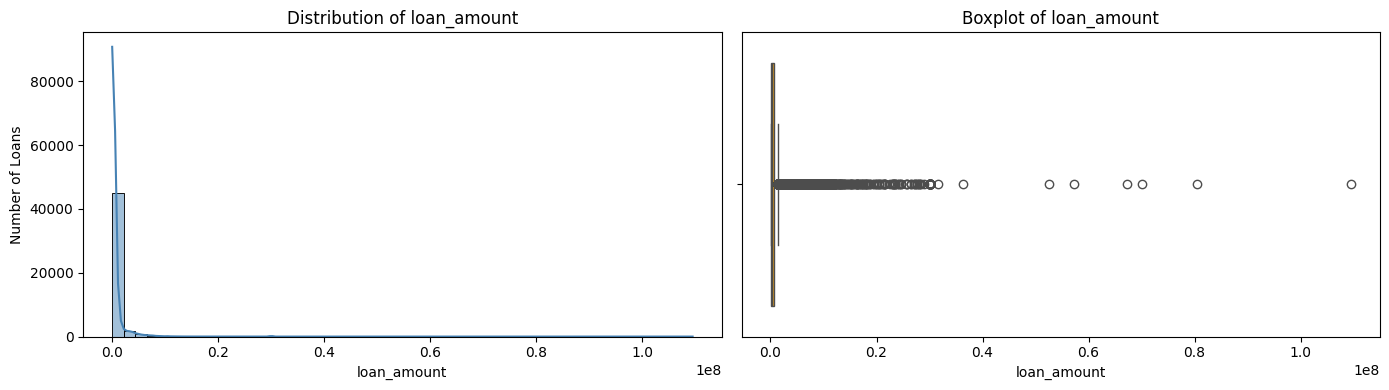

Interpretation: Histogram shows the distribution of loan_amount; the boxplot highlights potential outliers.



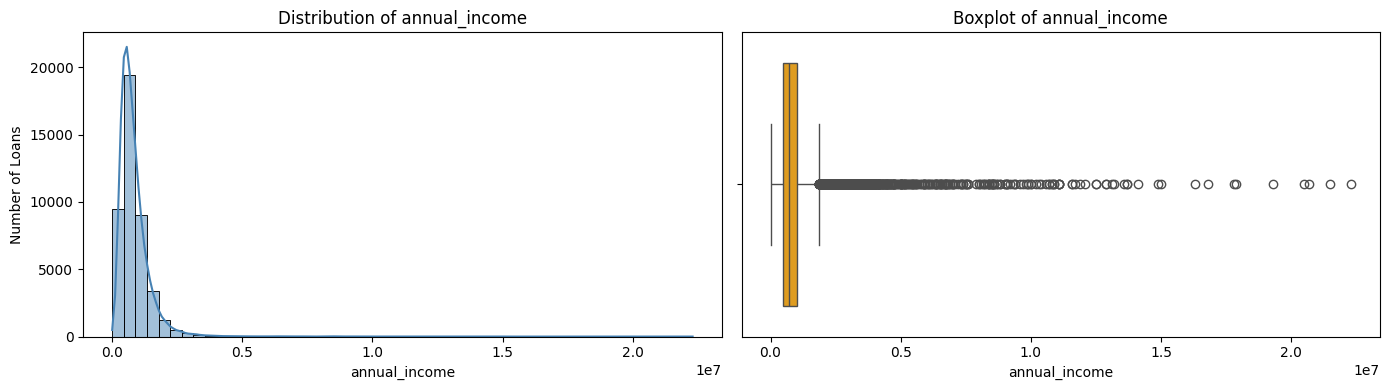

Interpretation: Histogram shows the distribution of annual_income; the boxplot highlights potential outliers.



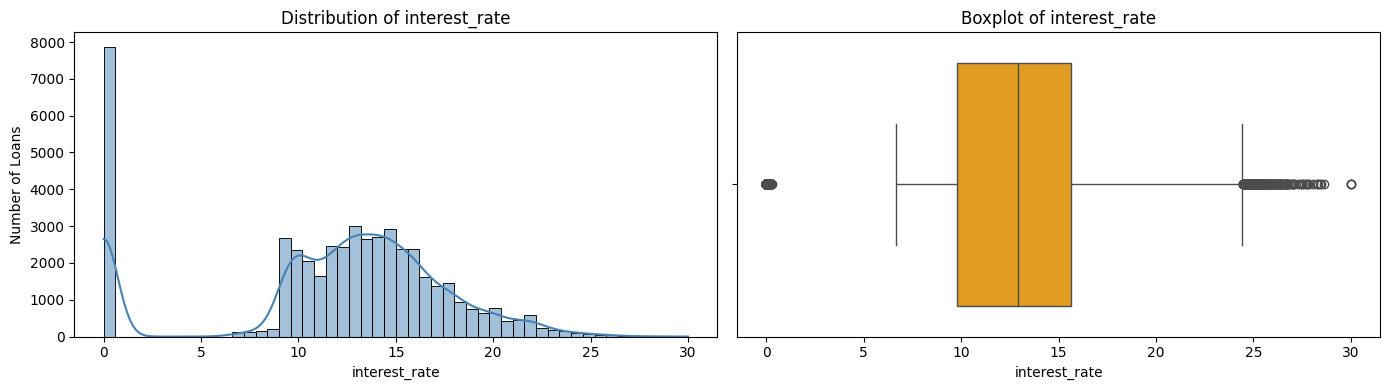

Interpretation: Histogram shows the distribution of interest_rate; the boxplot highlights potential outliers.



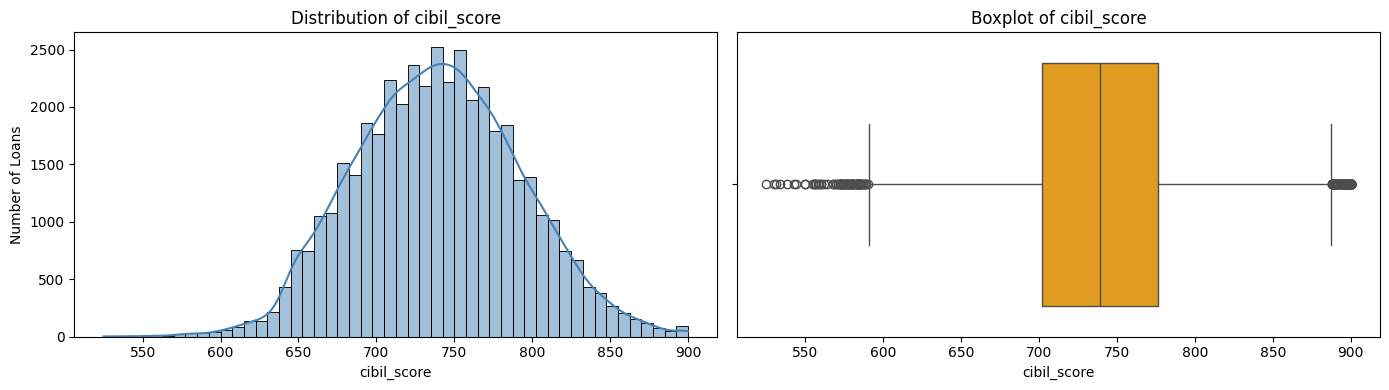

Interpretation: Histogram shows the distribution of cibil_score; the boxplot highlights potential outliers.



In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    "loan_amount",
    "annual_income",
    "interest_rate",
    "cibil_score"
]

for col in columns:

    data = pd.to_numeric(df[col], errors="coerce").dropna()

    # CIBIL -1 means no credit history, not a numeric score
    if col == "cibil_score":
        data = data[data != -1]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Histogram
    sns.histplot(
        data,
        bins=50,
        kde=True,
        ax=axes[0],
        color="steelblue"
    )

    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Number of Loans")

    # Boxplot
    sns.boxplot(
        x=data,
        ax=axes[1],
        color="orange"
    )

    axes[1].set_title(f"Boxplot of {col}")
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

    print(
        f"Interpretation: Histogram shows the distribution of {col}; "
        "the boxplot highlights potential outliers.\n"
    )


The maximum loan amount distributed is very less as the distribution is right skewed distribution , annual income is also right skewed but normal distribution , the intereset rate is no cost emi maximummly , and the distribution of cibil score is normal but has some small values on the left side.

In [ ]:

columns_to_analyze = [
    "product_type",
    "sourcing_channel",
    "city_tier",
    "employment_type"
]

for col in columns_to_analyze:

    summary = (
        df.groupby(col, dropna=False)
        .agg(
            Number_of_Loans=("loan_id", "count"),
            Total_Amount_Lent=("loan_amount", "sum"),
            Average_Loan_Amount=("loan_amount", "mean")
        )
        .sort_values("Total_Amount_Lent", ascending=False)
    )

    summary["Loan_Count_%"] = (
        summary["Number_of_Loans"] /
        summary["Number_of_Loans"].sum() * 100
    ).round(2)

    summary["Amount_Lent_%"] = (
        summary["Total_Amount_Lent"] /
        summary["Total_Amount_Lent"].sum() * 100
    ).round(2)

    print(f"\n{'='*60}")
    print(f"Loan Breakdown by {col}")
    print(f"{'='*60}")

    display(summary.round(2))



Loan Breakdown by product_type


,Number_of_Loans,Total_Amount_Lent,Average_Loan_Amount,Loan_Count_%,Amount_Lent_%
product_type,,,,,
Home Loan,3012,1.611324e+10,5349680.94,6.28,47.88
Personal Loan,25430,1.439725e+10,566152.05,53.05,42.78
Business Loan,2142,1.933119e+09,902483.24,4.47,5.74
Gold Loan,4006,4.986093e+08,124465.63,8.36,1.48
Consumer Durable,10509,4.352804e+08,41419.77,21.92,1.29
Two Wheeler,2841,2.735232e+08,96277.07,5.93,0.81



Loan Breakdown by sourcing_channel


,Number_of_Loans,Total_Amount_Lent,Average_Loan_Amount,Loan_Count_%,Amount_Lent_%
sourcing_channel,,,,,
DSA,10702,1.267438e+10,1184299.78,22.32,37.66
Branch,15105,1.167729e+10,773074.67,31.51,34.70
Digital App,10747,4.418040e+09,411095.19,22.42,13.13
Telesales,3969,2.667368e+09,672050.48,8.28,7.93
Fintech Partner,7417,2.213940e+09,298495.37,15.47,6.58



Loan Breakdown by city_tier


,Number_of_Loans,Total_Amount_Lent,Average_Loan_Amount,Loan_Count_%,Amount_Lent_%
city_tier,,,,,
1,25060,1.950330e+10,778264.30,52.27,57.96
2,15754,1.034232e+10,656488.25,32.86,30.73
3,7126,3.805398e+09,534016.06,14.86,11.31



Loan Breakdown by employment_type


,Number_of_Loans,Total_Amount_Lent,Average_Loan_Amount,Loan_Count_%,Amount_Lent_%
employment_type,,,,,
Salaried,29477,1.960120e+10,664966.01,61.49,58.25
Self-Employed Business,12470,9.227443e+09,739971.35,26.01,27.42
Self-Employed Professional,5993,4.822372e+09,804667.40,12.50,14.33


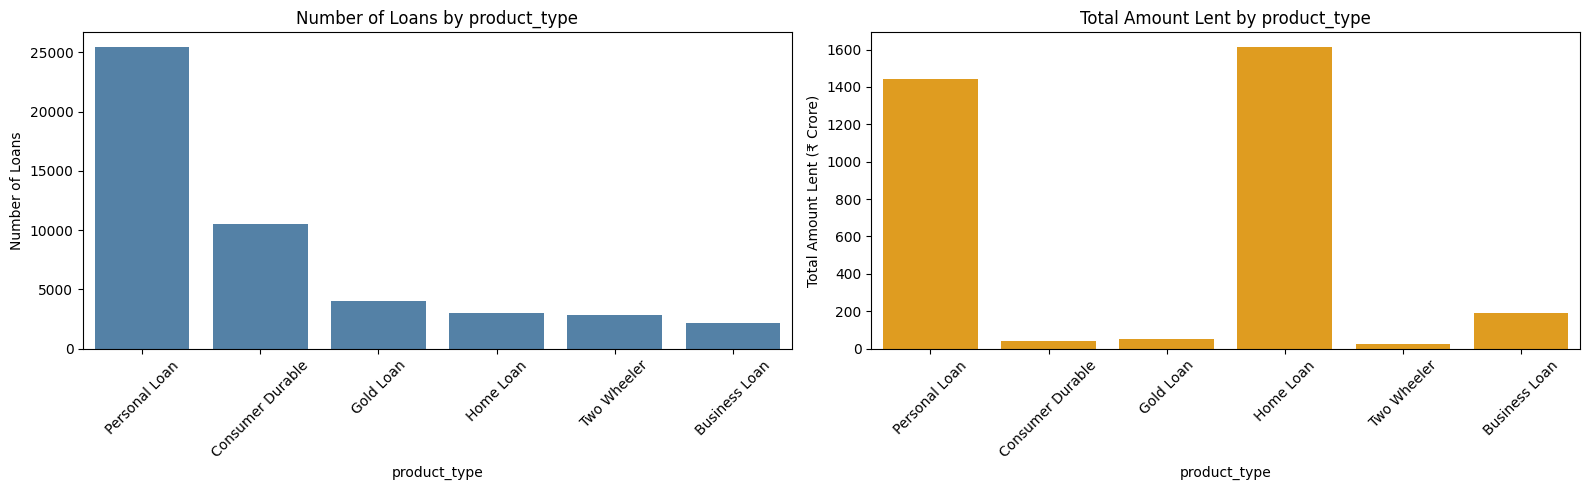

Interpretation: Compare the loan count and total lending across product_type to see whether the categories with the most loans also receive the largest share of lending.



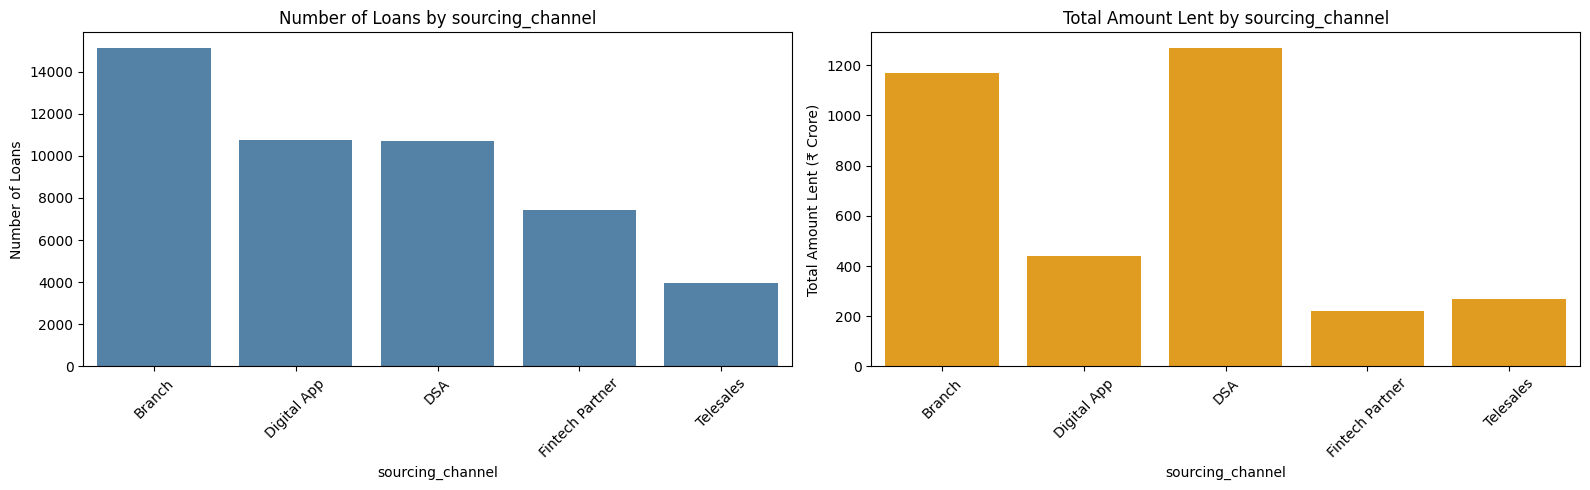

Interpretation: Compare the loan count and total lending across sourcing_channel to see whether the categories with the most loans also receive the largest share of lending.



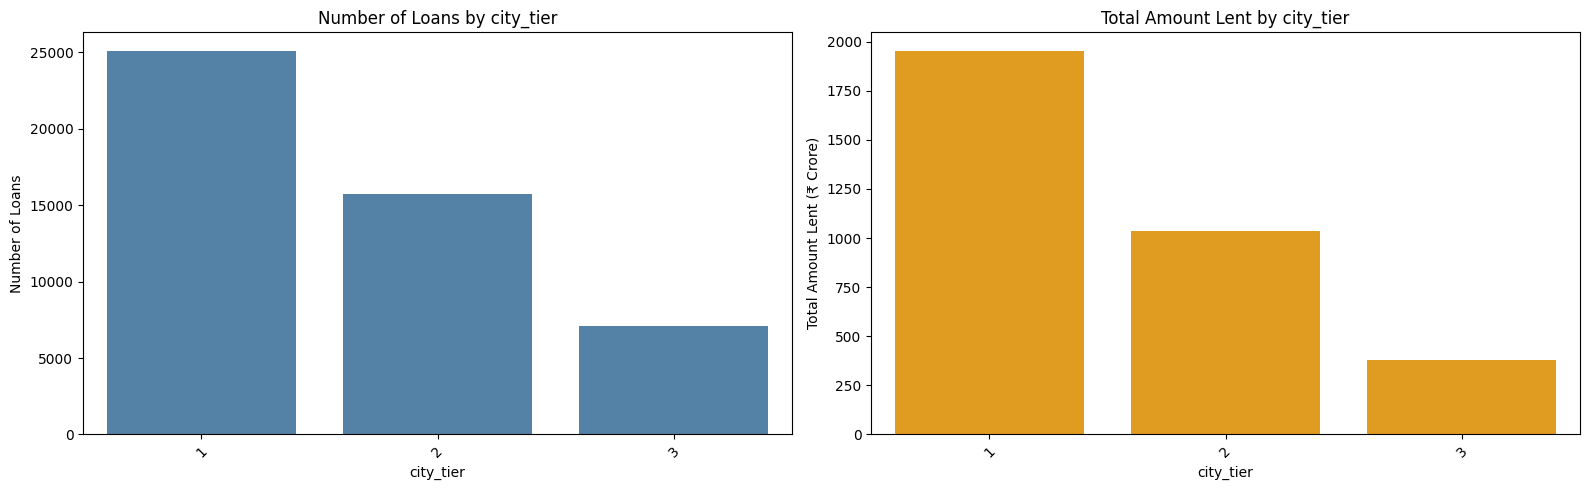

Interpretation: Compare the loan count and total lending across city_tier to see whether the categories with the most loans also receive the largest share of lending.



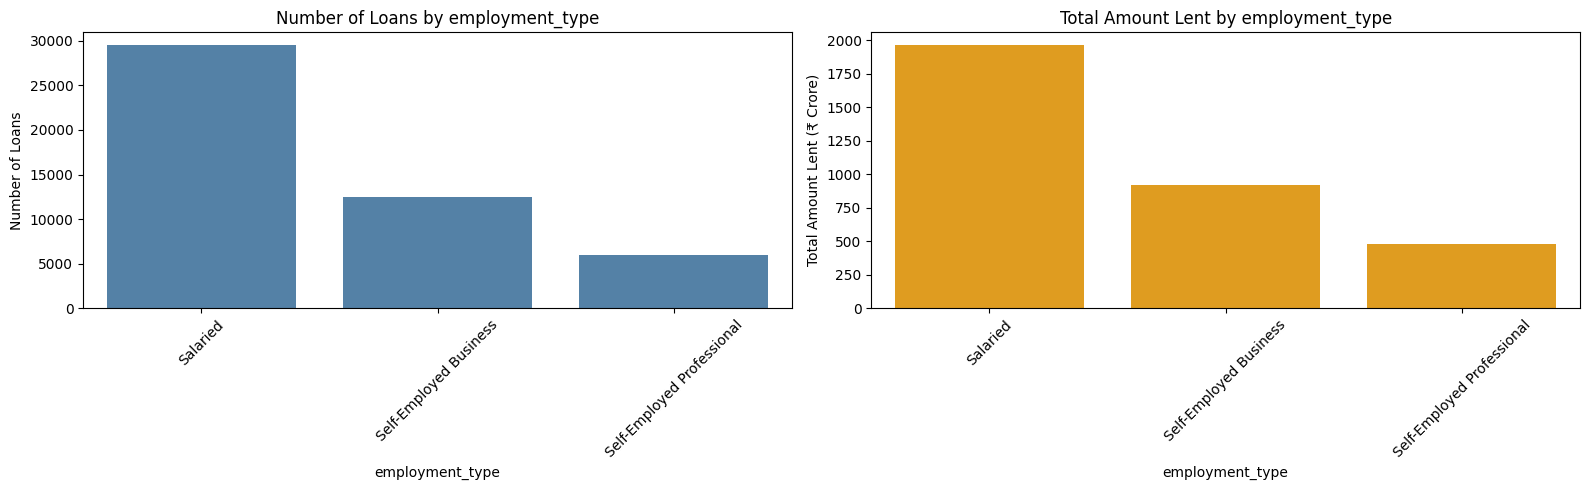

Interpretation: Compare the loan count and total lending across employment_type to see whether the categories with the most loans also receive the largest share of lending.



In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

for col in columns_to_analyze:

    summary = (
        df.groupby(col, dropna=False)
        .agg(
            Loan_Count=("loan_id", "count"),
            Total_Amount=("loan_amount", "sum")
        )
        .sort_values("Loan_Count", ascending=False)
        .reset_index()
    )

    summary[col] = summary[col].fillna("Missing").astype(str)
    summary["Amount_Crore"] = summary["Total_Amount"] / 1e7

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Chart 1: Loan count
    sns.barplot(
        data=summary,
        x=col,
        y="Loan_Count",
        ax=axes[0],
        color="steelblue"
    )

    axes[0].set_title(f"Number of Loans by {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Number of Loans")
    axes[0].tick_params(axis="x", rotation=45)

    # Chart 2: Total amount lent
    sns.barplot(
        data=summary,
        x=col,
        y="Amount_Crore",
        ax=axes[1],
        color="orange"
    )

    axes[1].set_title(f"Total Amount Lent by {col}")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Total Amount Lent (₹ Crore)")
    axes[1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

    print(
        f"Interpretation: Compare the loan count and total lending "
        f"across {col} to see whether the categories with the most "
        f"loans also receive the largest share of lending.\n"
    )


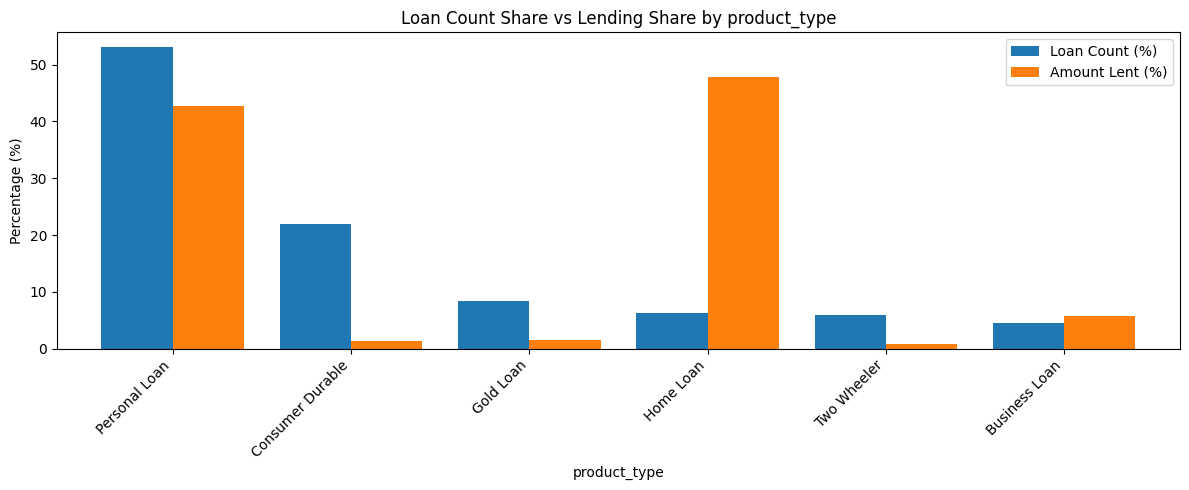

Interpretation: Larger differences between the two percentages indicate differences in average loan size across product_type categories.



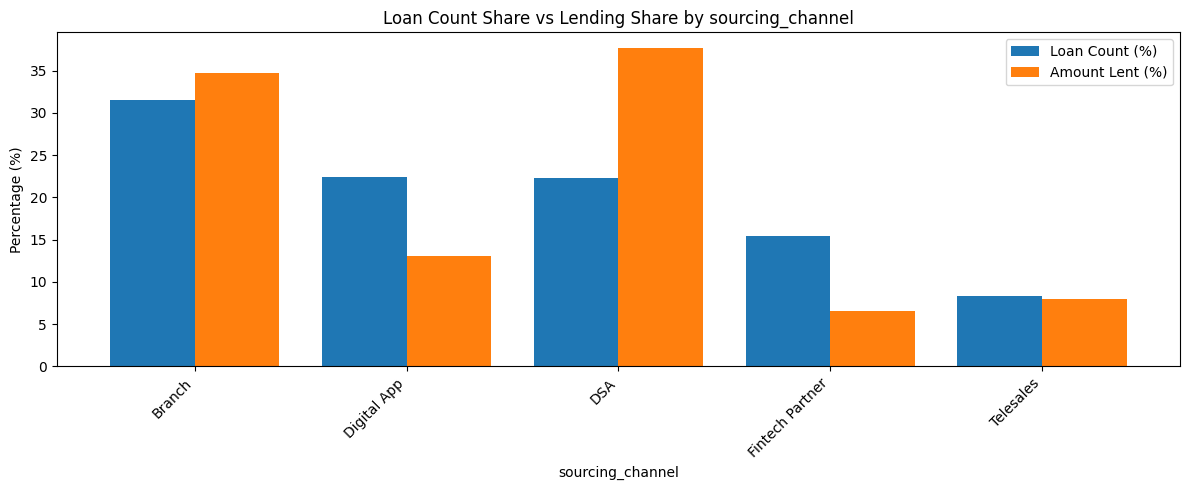

Interpretation: Larger differences between the two percentages indicate differences in average loan size across sourcing_channel categories.



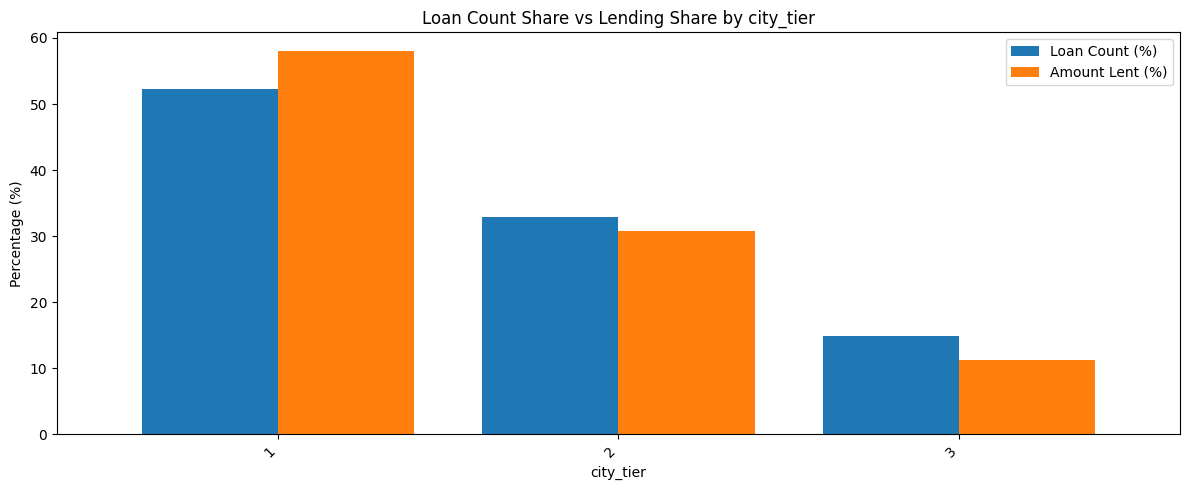

Interpretation: Larger differences between the two percentages indicate differences in average loan size across city_tier categories.



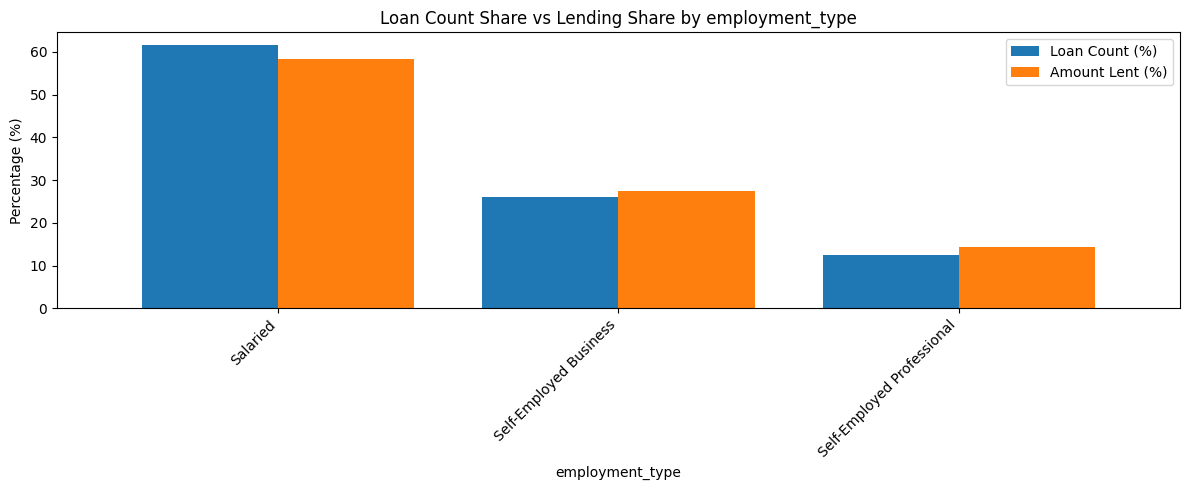

Interpretation: Larger differences between the two percentages indicate differences in average loan size across employment_type categories.



In [ ]:

for col in columns_to_analyze:

    summary = (
        df.groupby(col, dropna=False)
        .agg(
            Loan_Count=("loan_id", "count"),
            Total_Amount=("loan_amount", "sum")
        )
    )

    summary["Loan_Count_%"] = (
        summary["Loan_Count"] / summary["Loan_Count"].sum() * 100
    )

    summary["Amount_Lent_%"] = (
        summary["Total_Amount"] / summary["Total_Amount"].sum() * 100
    )

    comparison = summary[
        ["Loan_Count_%", "Amount_Lent_%"]
    ].sort_values("Loan_Count_%", ascending=False)

    comparison.plot(
        kind="bar",
        figsize=(12, 5),
        width=0.8
    )

    plt.title(f"Loan Count Share vs Lending Share by {col}")
    plt.xlabel(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=45, ha="right")
    plt.legend(["Loan Count (%)", "Amount Lent (%)"])
    plt.tight_layout()
    plt.show()

    print(
        f"Interpretation: Larger differences between the two "
        f"percentages indicate differences in average loan size "
        f"across {col} categories.\n"
    )

Personal Loans are more but the amount given to them is less , the housing loans are less but take lot more of the value
The direct selling agent are responsible more for giving housing loans as they do have the highest share in the amount lent , tier one needs has more need so they get more loan
Then Salaried guys get more loan as it is believed they will pay on time due to salary.

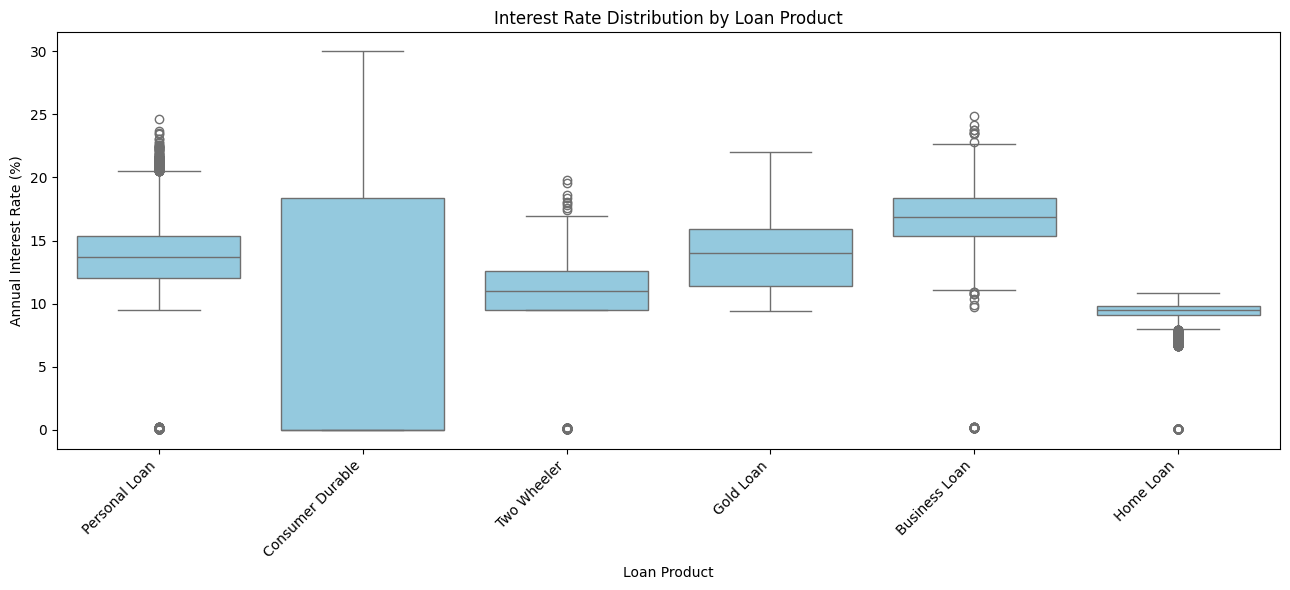

Interpretation: This boxplot compares median interest rates, variability and potential outliers across loan products.


In [ ]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df,
    x="product_type",
    y="interest_rate",
    color="skyblue"
)

plt.title("Interest Rate Distribution by Loan Product")
plt.xlabel("Loan Product")
plt.ylabel("Annual Interest Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(
    "Interpretation: This boxplot compares median interest rates, "
    "variability and potential outliers across loan products."
)


The highest median for loan is buisness loan while home loan is lower even personal loan is also showing high frequency

**D**

In [ ]:

# Define bad loan statuses
bad_statuses = ["Default", "Charged Off", "Auctioned"]

# Create bad loan indicator
df["is_bad_loan"] = (
    df["loan_status"].str.strip().isin(bad_statuses)
).astype(int)

# Filter older loans for D2-D6
df_risk = df[
    df["disbursal_date"] < pd.Timestamp("2024-04-01")
].copy()

print("Total loans:", len(df))
print("Total bad loans:", df["is_bad_loan"].sum())

print("\nLoans disbursed before 1 April 2024:", len(df_risk))
print("Bad loans in older dataset:", df_risk["is_bad_loan"].sum())

print(
    "Overall bad-loan rate for older loans:",
    round(df_risk["is_bad_loan"].mean() * 100, 2),
    "%"
)


Total loans: 47940
Total bad loans: 2923

Loans disbursed before 1 April 2024: 26743
Bad loans in older dataset: 1985
Overall bad-loan rate for older loans: 7.42 %


In [ ]:

# Create a copy for D1 analysis
df_d1 = df.copy()

# Define bad loans
bad_statuses = ["Default", "Charged Off", "Auctioned"]

df_d1["is_bad_loan"] = (
    df_d1["loan_status"].str.strip().isin(bad_statuses)
).astype(int)

# Extract disbursal quarter
df_d1["disbursal_quarter"] = (
    df_d1["disbursal_date"].dt.to_period("Q")
)

# Calculate quarterly bad-loan rate
quarterly_bad_rate = (
    df_d1.groupby("disbursal_quarter")
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum")
    )
    .reset_index()
)

quarterly_bad_rate["Bad_Loan_Rate"] = (
    quarterly_bad_rate["Bad_Loans"] /
    quarterly_bad_rate["Total_Loans"] * 100
).round(2)

display(quarterly_bad_rate)


,disbursal_quarter,Total_Loans,Bad_Loans,Bad_Loan_Rate
0,2022Q1,1845,113,6.12
1,2022Q2,2056,124,6.03
2,2022Q3,2248,142,6.32
3,2022Q4,2964,182,6.14
4,2023Q1,2905,159,5.47
5,2023Q2,2893,207,7.16
6,2023Q3,3302,311,9.42
7,2023Q4,4430,364,8.22
8,2024Q1,4100,383,9.34
9,2024Q2,3813,288,7.55


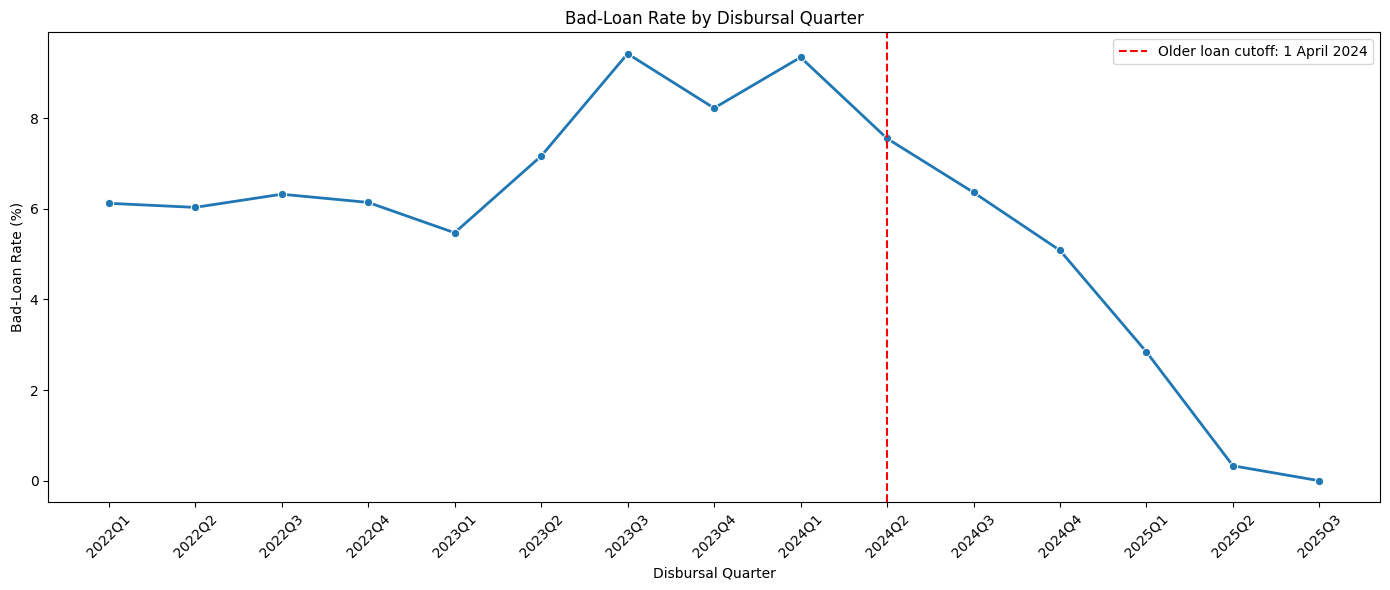

Interpretation: Compare the bad-loan rates of older quarters against newer quarters to identify whether recent loans show artificially lower default rates.


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

quarterly_bad_rate["Quarter_Label"] = (
    quarterly_bad_rate["disbursal_quarter"].astype(str)
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=quarterly_bad_rate,
    x="Quarter_Label",
    y="Bad_Loan_Rate",
    marker="o",
    linewidth=2
)

# Cutoff: 1 April 2024 = beginning of 2024Q2
plt.axvline(
    x="2024Q2",
    color="red",
    linestyle="--",
    label="Older loan cutoff: 1 April 2024"
)

plt.title("Bad-Loan Rate by Disbursal Quarter")
plt.xlabel("Disbursal Quarter")
plt.ylabel("Bad-Loan Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Interpretation: Compare the bad-loan rates of older "
    "quarters against newer quarters to identify whether "
    "recent loans show artificially lower default rates."
)


### D1. Bad-Loan Rate by Disbursal Quarter — Key Findings

The quarterly analysis reveals that bad-loan rates remained relatively stable at around 5.5%–6.3% during 2022 but increased substantially during 2023, reaching approximately 9.4% in Q3 2023 and 9.3% in Q1 2024.

After Q1 2024, bad-loan rates declined consistently, reaching approximately 0.3% in Q2 2025 and 0% in Q3 2025.

However, this decline should not automatically be interpreted as an improvement in lending quality. Newer loans have had less time to develop repayment problems, resulting in artificially low observed bad-loan rates. This effect is known as **loan seasoning**.

Therefore, loans disbursed before 1 April 2024 are used for the subsequent risk analysis to allow a longer repayment observation period and reduce bias caused by differences in loan age.

**Key takeaway:** The apparent improvement in recent bad-loan rates may be primarily due to shorter observation periods rather than genuinely lower credit risk.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create an independent copy
df_d2 = df_risk.copy()

# Ensure bad-loan indicator is available
bad_statuses = ["Default", "Charged Off", "Auctioned"]

df_d2["is_bad_loan"] = (
    df_d2["loan_status"].str.strip().isin(bad_statuses)
).astype(int)

# CIBIL score -1 means no credit history
# Keep it as a separate category
cibil_bins = [299, 600, 650, 700, 750, 800, 900]
cibil_labels = [
    "300-599", "600-649", "650-699",
    "700-749", "750-799", "800-900"
]

df_d2["cibil_group"] = pd.cut(
    df_d2["cibil_score"],
    bins=cibil_bins,
    labels=cibil_labels
).astype("object")

df_d2.loc[
    df_d2["cibil_score"] == -1, "cibil_group"
] = "No Credit History"

df_d2["cibil_group"] = df_d2["cibil_group"].fillna(
    "Missing/Invalid"
)

# Create age groups
age_bins = [17, 25, 35, 45, 55, 65, np.inf]
age_labels = [
    "18-25", "26-35", "36-45",
    "46-55", "56-65", "66+"
]

df_d2["age_group"] = pd.cut(
    df_d2["age"],
    bins=age_bins,
    labels=age_labels
).astype("object").fillna("Missing/Invalid")

print("Dataset prepared successfully!")
print("Total loans:", len(df_d2))
print("Overall bad-loan rate:",
      round(df_d2["is_bad_loan"].mean() * 100, 2), "%")


Dataset prepared successfully!
Total loans: 26743
Overall bad-loan rate: 7.42 %


In [ ]:

factors = [
    "product_type",
    "sourcing_channel",
    "cibil_group",
    "age_group",
    "employer_category",
    "city_tier"
]

# Store results for further analysis
risk_summaries = {}

for factor in factors:

    # Employer category only applies to salaried customers
    if factor == "employer_category":
        temp = df_d2[
            df_d2["employment_type"]
            .str.strip()
            .str.lower() == "salaried"
        ].copy()
    else:
        temp = df_d2.copy()

    summary = (
        temp.groupby(factor, dropna=False, observed=True)
        .agg(
            Total_Loans=("loan_id", "count"),
            Bad_Loans=("is_bad_loan", "sum")
        )
        .reset_index()
    )

    summary["Bad_Loan_Rate_%"] = (
        summary["Bad_Loans"] /
        summary["Total_Loans"] * 100
    ).round(2)

    summary = summary.sort_values(
        "Bad_Loan_Rate_%",
        ascending=False
    )

    risk_summaries[factor] = summary

    print(f"\n{'='*65}")
    print(f"BAD-LOAN RATE BY {factor.upper()}")
    print(f"{'='*65}")

    display(summary)



BAD-LOAN RATE BY PRODUCT_TYPE


,product_type,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
0,Business Loan,1261,173,13.72
4,Personal Loan,14148,1405,9.93
1,Consumer Durable,5355,230,4.30
5,Two Wheeler,1714,72,4.20
2,Gold Loan,2487,87,3.50
3,Home Loan,1778,18,1.01



BAD-LOAN RATE BY SOURCING_CHANNEL


,sourcing_channel,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
3,Fintech Partner,2571,412,16.02
4,Telesales,2378,226,9.50
2,Digital App,6034,431,7.14
1,DSA,6507,422,6.49
0,Branch,9253,494,5.34



BAD-LOAN RATE BY CIBIL_GROUP


,cibil_group,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
0,300-599,55,18,32.73
1,600-649,765,167,21.83
6,Missing/Invalid,28,4,14.29
2,650-699,4727,626,13.24
7,No Credit History,2255,230,10.20
3,700-749,8448,610,7.22
4,750-799,7187,276,3.84
5,800-900,3278,54,1.65


... (2 outputs left out)


BAD-LOAN RATE BY EMPLOYER_CATEGORY


,employer_category,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
4,Proprietorship,2063,181,8.77
5,Startup,1592,139,8.73
3,Private Ltd,5996,446,7.44
6,NaN,686,49,7.14
2,PSU,1126,62,5.51
1,MNC,3142,158,5.03
0,Government,1857,89,4.79



BAD-LOAN RATE BY CITY_TIER


,city_tier,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
2,3,3963,327,8.25
1,2,8783,669,7.62
0,1,13997,989,7.07


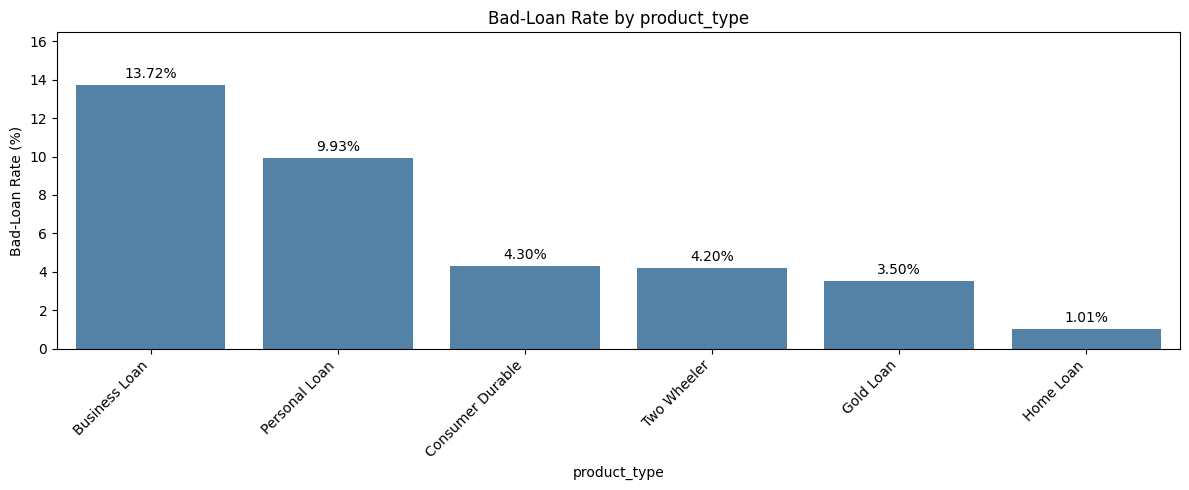

Interpretation: Higher bars indicate categories with higher observed bad-loan rates within product_type.



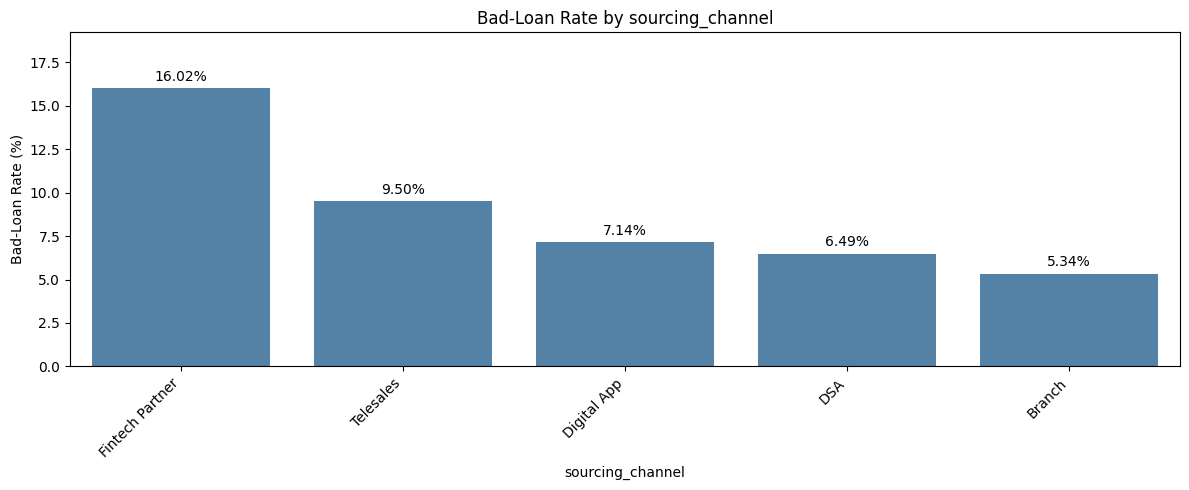

Interpretation: Higher bars indicate categories with higher observed bad-loan rates within sourcing_channel.



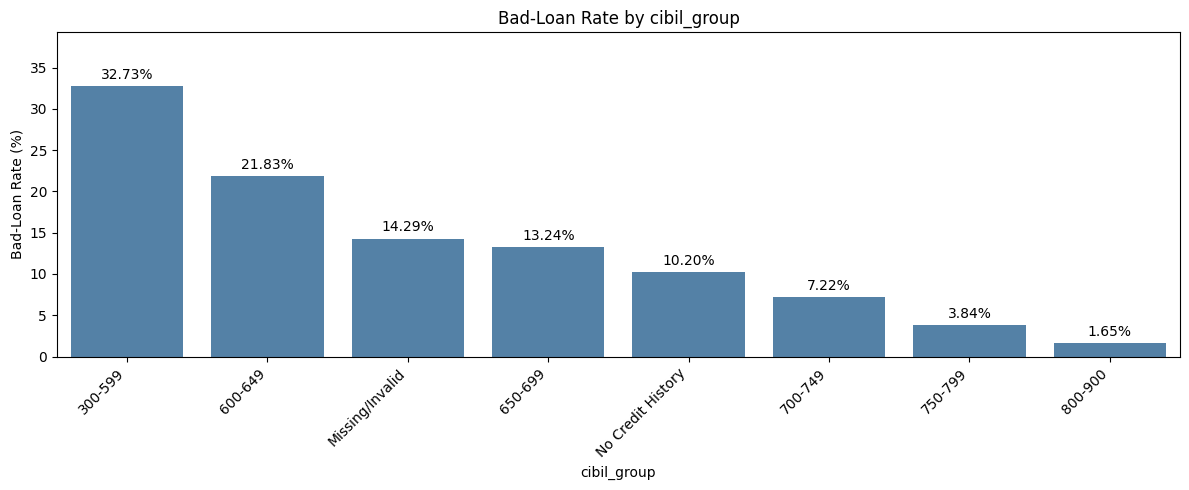

Interpretation: Higher bars indicate categories with higher observed bad-loan rates within cibil_group.



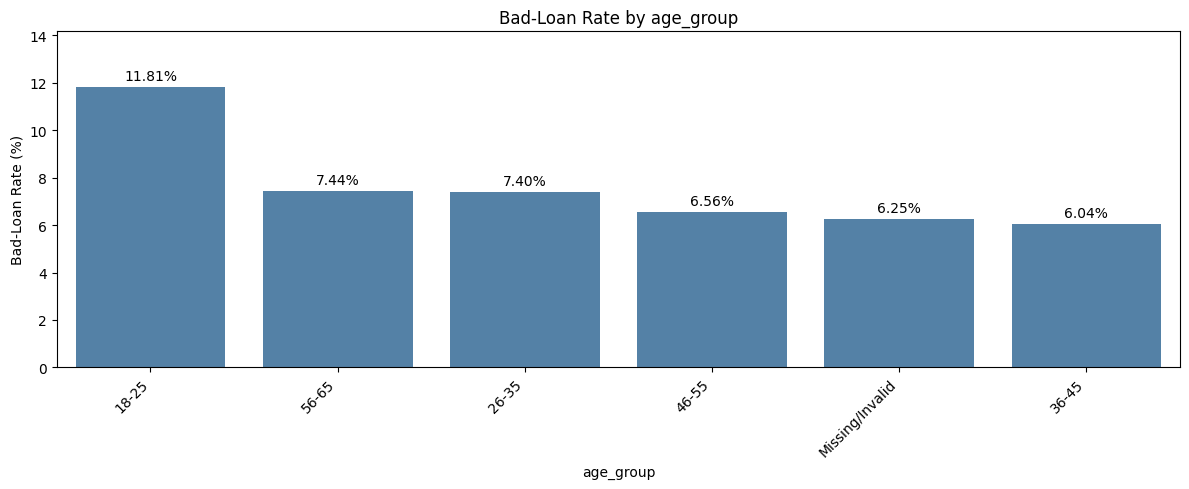

Interpretation: Higher bars indicate categories with higher observed bad-loan rates within age_group.



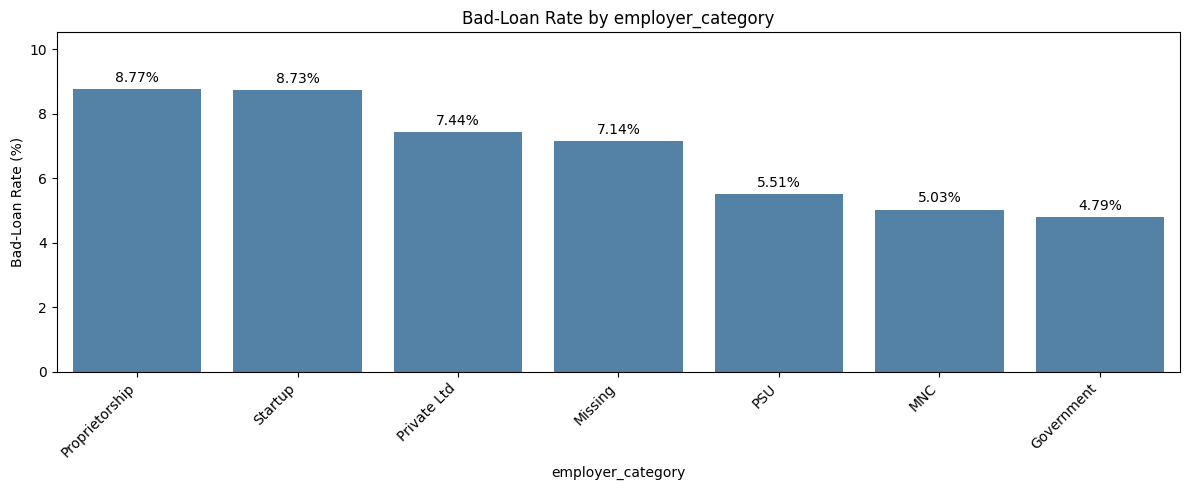

Interpretation: Higher bars indicate categories with higher observed bad-loan rates within employer_category.



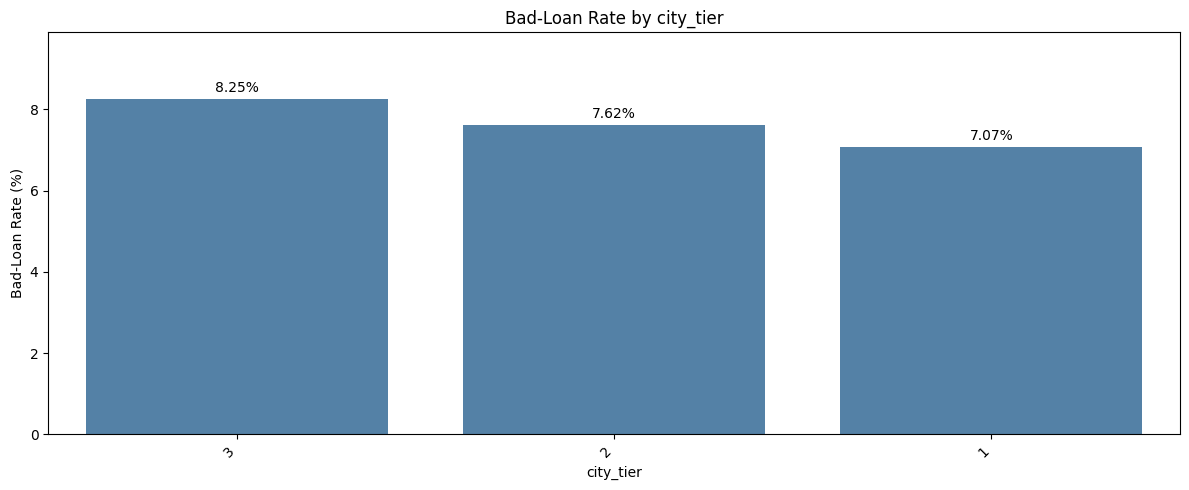

Interpretation: Higher bars indicate categories with higher observed bad-loan rates within city_tier.



In [ ]:

for factor, summary in risk_summaries.items():

    plot_data = summary.copy()
    plot_data[factor] = (
        plot_data[factor].fillna("Missing").astype(str)
    )

    plt.figure(figsize=(12, 5))

    ax = sns.barplot(
        data=plot_data,
        x=factor,
        y="Bad_Loan_Rate_%",
        color="steelblue"
    )

    # Add percentage labels
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)

    plt.title(f"Bad-Loan Rate by {factor}")
    plt.xlabel(factor)
    plt.ylabel("Bad-Loan Rate (%)")
    plt.xticks(rotation=45, ha="right")

    plt.ylim(
        0,
        max(plot_data["Bad_Loan_Rate_%"].max() * 1.2, 1)
    )

    plt.tight_layout()
    plt.show()

    print(
        f"Interpretation: Higher bars indicate categories "
        f"with higher observed bad-loan rates within {factor}.\n"
    )


In [ ]:

factor_comparison = []

min_loans = 100

for factor, summary in risk_summaries.items():

    valid_summary = summary[
        summary["Total_Loans"] >= min_loans
    ].copy()

    # Exclude unknown categories from ranking
    valid_summary = valid_summary[
        ~valid_summary[factor].astype(str).isin(
            ["Missing/Invalid", "nan", "None"]
        )
    ]

    if len(valid_summary) < 2:
        continue

    highest = valid_summary.loc[
        valid_summary["Bad_Loan_Rate_%"].idxmax()
    ]

    lowest = valid_summary.loc[
        valid_summary["Bad_Loan_Rate_%"].idxmin()
    ]

    spread = (
        highest["Bad_Loan_Rate_%"] -
        lowest["Bad_Loan_Rate_%"]
    )

    factor_comparison.append({
        "Factor": factor,
        "Highest_Risk_Group": str(highest[factor]),
        "Highest_Rate_%": highest["Bad_Loan_Rate_%"],
        "Lowest_Risk_Group": str(lowest[factor]),
        "Lowest_Rate_%": lowest["Bad_Loan_Rate_%"],
        "Difference_pp": round(spread, 2)
    })

factor_ranking = pd.DataFrame(
    factor_comparison
).sort_values("Difference_pp", ascending=False)

display(factor_ranking)

print("\nTOP 3 FACTORS WITH LARGEST BAD-LOAN RATE DIFFERENCES")
display(factor_ranking.head(3))


,Factor,Highest_Risk_Group,Highest_Rate_%,Lowest_Risk_Group,Lowest_Rate_%,Difference_pp
2,cibil_group,600-649,21.83,800-900,1.65,20.18
0,product_type,Business Loan,13.72,Home Loan,1.01,12.71
1,sourcing_channel,Fintech Partner,16.02,Branch,5.34,10.68
3,age_group,18-25,11.81,36-45,6.04,5.77
4,employer_category,Proprietorship,8.77,Government,4.79,3.98
5,city_tier,3.0,8.25,1.0,7.07,1.18



TOP 3 FACTORS WITH LARGEST BAD-LOAN RATE DIFFERENCES


,Factor,Highest_Risk_Group,Highest_Rate_%,Lowest_Risk_Group,Lowest_Rate_%,Difference_pp
2,cibil_group,600-649,21.83,800-900,1.65,20.18
0,product_type,Business Loan,13.72,Home Loan,1.01,12.71
1,sourcing_channel,Fintech Partner,16.02,Branch,5.34,10.68


The biggest difference is cibil score the less the more the chances of the bad loan , also business loan has lot more risk so the chances of getting bad are also high. Also Fintech partner loans have high risk too. The last bigger factor is age_group 18_25 don't have much credit history so the chances of going default are less.

D3

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate dataframe
df_d3 = df_risk.copy()

# Define bad loans
bad_statuses = ["Default", "Charged Off", "Auctioned"]

df_d3["is_bad_loan"] = (
    df_d3["loan_status"].str.strip().isin(bad_statuses)
).astype(int)

print("Total older loans:", len(df_d3))

# Missing values before handling
print("\nMissing values before handling:")
print(
    df_d3[
        ["annual_income", "existing_emi", "emi"]
    ].isna().sum()
)

# Assume existing EMI = 0 if customer has no existing loans
zero_existing = (
    df_d3["existing_emi"].isna() &
    df_d3["num_existing_loans"].eq(0)
)

print("\nMissing existing EMI replaced with zero:",
      zero_existing.sum())

df_d3.loc[zero_existing, "existing_emi"] = 0

# Keep only EMI repayment loans
# Bullet and Monthly Interest loans have different repayment structures
df_d3 = df_d3[
    df_d3["repayment_type"].str.strip().str.upper() == "EMI"
].copy()

print("EMI repayment loans:", len(df_d3))

# Remove records where burden cannot be calculated reliably
valid_mask = (
    df_d3["annual_income"].gt(0) &
    df_d3["existing_emi"].ge(0) &
    df_d3["emi"].ge(0) &
    df_d3[
        ["annual_income", "existing_emi", "emi"]
    ].notna().all(axis=1)
)

excluded_count = (~valid_mask).sum()

df_d3_clean = df_d3.loc[valid_mask].copy()

print("\nLoans excluded due to missing/invalid financial data:",
      excluded_count)

print("Loans included in EMI burden analysis:",
      len(df_d3_clean))

print(
    "Total older loans not included:",
    len(df_risk) - len(df_d3_clean)
)


Total older loans: 26743

Missing values before handling:
annual_income    2424
existing_emi     6491
emi              1064
dtype: int64

Missing existing EMI replaced with zero: 3361
EMI repayment loans: 24256

Loans excluded due to missing/invalid financial data: 4720
Loans included in EMI burden analysis: 19536
Total older loans not included: 7207


In [ ]:

# Calculate monthly income
df_d3_clean["monthly_income"] = (
    df_d3_clean["annual_income"] / 12
)

# Calculate EMI burden percentage
df_d3_clean["emi_burden_pct"] = (
    (
        df_d3_clean["existing_emi"] +
        df_d3_clean["emi"]
    ) /
    df_d3_clean["monthly_income"]
) * 100

# Summary statistics
print("EMI Burden Summary:")
display(df_d3_clean["emi_burden_pct"].describe())

# Inspect 20 random records
display(
    df_d3_clean[
        [
            "loan_id",
            "annual_income",
            "existing_emi",
            "emi",
            "monthly_income",
            "emi_burden_pct"
        ]
    ].sample(
        min(20, len(df_d3_clean)),
        random_state=42
    )
)


EMI Burden Summary:


,emi_burden_pct
count,19536.000000
mean,46.139004
std,27.237218
min,0.407228
25%,26.327459
50%,42.292508
75%,61.647952
max,396.778723


,loan_id,annual_income,existing_emi,emi,monthly_income,emi_burden_pct
13183,SFL2208141267,490000.0,0.0,5170.0,40833.333333,12.661224
25617,SFL2401100384,943000.0,27900.0,28150.0,78583.333333,71.325557
2344,SFL2403146045,610000.0,0.0,13710.0,50833.333333,26.970492
6923,SFL2303135158,604000.0,0.0,17971.0,50333.333333,35.703974
43683,SFL2308115469,381000.0,7300.0,30344.0,31750.000000,118.563780
22929,SFL2311109758,479000.0,6000.0,10152.0,39916.666667,40.464301
4807,SFL2301102860,1855000.0,14700.0,15172.0,154583.333333,19.324205
11612,SFL2302108536,677000.0,14800.0,23860.0,56416.666667,68.525849
915,SFL2310137804,1197000.0,36400.0,16040.0,99750.000000,52.571429
3961,SFL2203143721,1387000.0,0.0,17370.0,115583.333333,15.028118


In [ ]:

# Define EMI burden groups
burden_bins = [-np.inf, 30, 45, 60, 75, np.inf]

burden_labels = [
    "Below 30%",
    "30-45%",
    "45-60%",
    "60-75%",
    "Above 75%"
]

df_d3_clean["emi_burden_group"] = pd.cut(
    df_d3_clean["emi_burden_pct"],
    bins=burden_bins,
    labels=burden_labels,
    right=False
)

# Calculate bad-loan rates by group
burden_summary = (
    df_d3_clean.groupby(
        "emi_burden_group",
        observed=False
    )
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum")
    )
    .reset_index()
)

burden_summary["Bad_Loan_Rate_%"] = (
    burden_summary["Bad_Loans"] /
    burden_summary["Total_Loans"] * 100
).round(2)

display(burden_summary)


,emi_burden_group,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
0,Below 30%,5982,355,5.93
1,30-45%,4577,259,5.66
2,45-60%,3730,258,6.92
3,60-75%,2544,246,9.67
4,Above 75%,2703,441,16.32


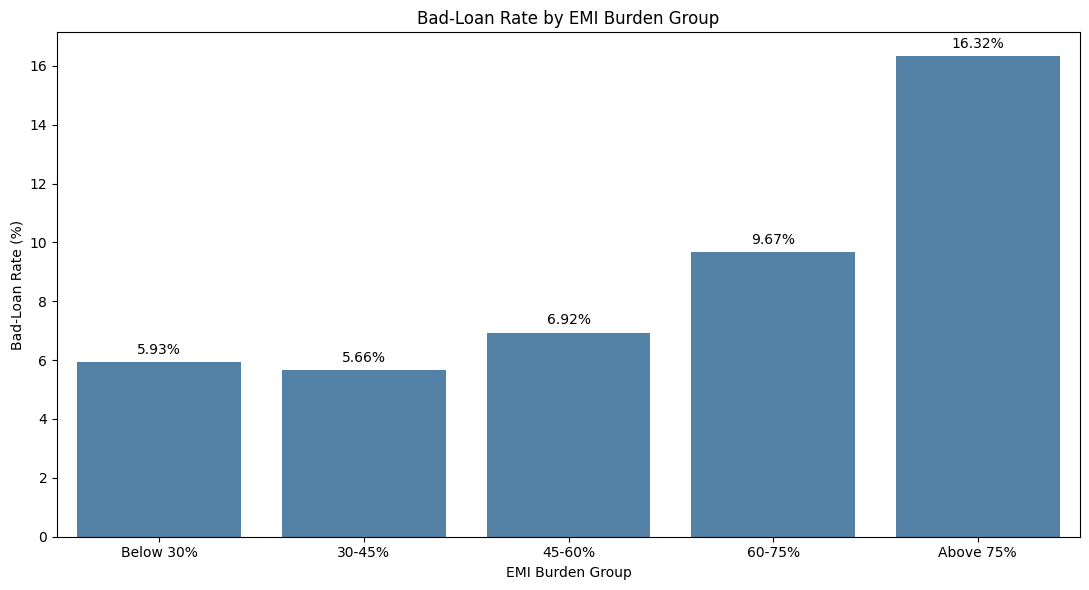

Interpretation: This chart shows how the observed bad-loan rate varies with the share of monthly income committed to loan repayments.


In [ ]:

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=burden_summary,
    x="emi_burden_group",
    y="Bad_Loan_Rate_%",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Bad-Loan Rate by EMI Burden Group")
plt.xlabel("EMI Burden Group")
plt.ylabel("Bad-Loan Rate (%)")

plt.tight_layout()
plt.show()

print(
    "Interpretation: This chart shows how the observed "
    "bad-loan rate varies with the share of monthly income "
    "committed to loan repayments."
)


In [ ]:

all_old = df_risk.copy()

is_emi = (
    all_old["repayment_type"]
    .str.strip().str.upper().eq("EMI")
)

emi_old = all_old.loc[is_emi].copy()

existing_missing_zero = (
    emi_old["existing_emi"].isna() &
    emi_old["num_existing_loans"].eq(0)
)

existing_unavailable = (
    emi_old["existing_emi"].isna() &
    emi_old["num_existing_loans"].gt(0)
)

invalid_income = (
    emi_old["annual_income"].isna() |
    emi_old["annual_income"].le(0)
)

invalid_emi = (
    emi_old["emi"].isna() |
    emi_old["emi"].lt(0)
)

# Mutually exclusive exclusion reasons
exclusion_reason = np.select(
    [
        invalid_income,
        existing_unavailable,
        invalid_emi,
        emi_old["existing_emi"].isna() & ~existing_missing_zero
    ],
    [
        "Missing/Invalid Annual Income",
        "Missing Existing EMI (Existing Loans > 0)",
        "Missing/Invalid Current EMI",
        "Missing Existing EMI (Unknown Loan Count)"
    ],
    default="Included"
)

exclusion_report = pd.Series(
    exclusion_reason
).value_counts().rename_axis(
    "Reason"
).reset_index(name="Loan_Count")

other_repayments = len(all_old) - len(emi_old)

exclusion_report = pd.concat(
    [
        exclusion_report,
        pd.DataFrame({
            "Reason": ["Non-EMI Repayment Type"],
            "Loan_Count": [other_repayments]
        })
    ],
    ignore_index=True
)

display(exclusion_report)

print("Total older loans:", len(all_old))
print("Loans included:", len(df_d3_clean))
print("Total loans excluded:",
      len(all_old) - len(df_d3_clean))


,Reason,Loan_Count
0,Included,19536
1,Missing Existing EMI (Existing Loans > 0),2539
2,Missing/Invalid Annual Income,2181
3,Non-EMI Repayment Type,2487


Total older loans: 26743
Loans included: 19536
Total loans excluded: 7207


The emi burden increases with the increase in bad loan rate.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_d4 = df_risk.copy()

bad_statuses = ["Default", "Charged Off", "Auctioned"]

df_d4["is_bad_loan"] = (
    df_d4["loan_status"]
    .str.strip()
    .isin(bad_statuses)
).astype(int)

# Overall bad-loan rates by channel
channel_summary = (
    df_d4.groupby("sourcing_channel")
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum"),
        Average_CIBIL=("cibil_score", lambda x: x[x >= 300].mean()),
        Median_Loan_Amount=("loan_amount", "median"),
        Median_Interest_Rate=("interest_rate", "median")
    )
)

channel_summary["Bad_Loan_Rate_%"] = (
    channel_summary["Bad_Loans"] /
    channel_summary["Total_Loans"] * 100
).round(2)

display(
    channel_summary.sort_values(
        "Bad_Loan_Rate_%", ascending=False
    ).round(2)
)


,Total_Loans,Bad_Loans,Average_CIBIL,Median_Loan_Amount,Median_Interest_Rate,Bad_Loan_Rate_%
sourcing_channel,,,,,,
Fintech Partner,2571,412,710.81,116800.0,15.20,16.02
Telesales,2378,226,743.98,441000.0,13.90,9.50
Digital App,6034,431,744.47,268000.0,13.05,7.14
DSA,6507,422,744.21,368000.0,12.65,6.49
Branch,9253,494,743.75,199400.0,12.20,5.34


In [ ]:

# Exclude -1 and invalid CIBIL values from average
df_d4["valid_cibil"] = df_d4["cibil_score"].where(
    df_d4["cibil_score"].between(300, 900)
)

# No credit history indicator
df_d4["no_credit_history"] = (
    df_d4["cibil_score"] == -1
).astype(int)

customer_profile = (
    df_d4.groupby("sourcing_channel")
    .agg(
        Total_Loans=("loan_id", "count"),
        Average_CIBIL=("valid_cibil", "mean"),
        Median_Income=("annual_income", "median"),
        Average_Age=("age", "mean"),
        Median_Loan_Amount=("loan_amount", "median"),
        Average_Interest_Rate=("interest_rate", "mean"),
        No_Credit_History_Percent=("no_credit_history", "mean")
    )
)

customer_profile["No_Credit_History_Percent"] *= 100

display(customer_profile.round(2))


,Total_Loans,Average_CIBIL,Median_Income,Average_Age,Median_Loan_Amount,Average_Interest_Rate,No_Credit_History_Percent
sourcing_channel,,,,,,,
Branch,9253,743.75,724000.0,35.25,199400.0,11.54,4.90
DSA,6507,744.21,720000.0,35.07,368000.0,12.11,4.56
Digital App,6034,744.47,724000.0,35.02,268000.0,11.43,11.48
Fintech Partner,2571,710.81,603000.0,27.20,116800.0,11.71,25.71
Telesales,2378,743.98,730000.0,35.30,441000.0,13.15,6.35


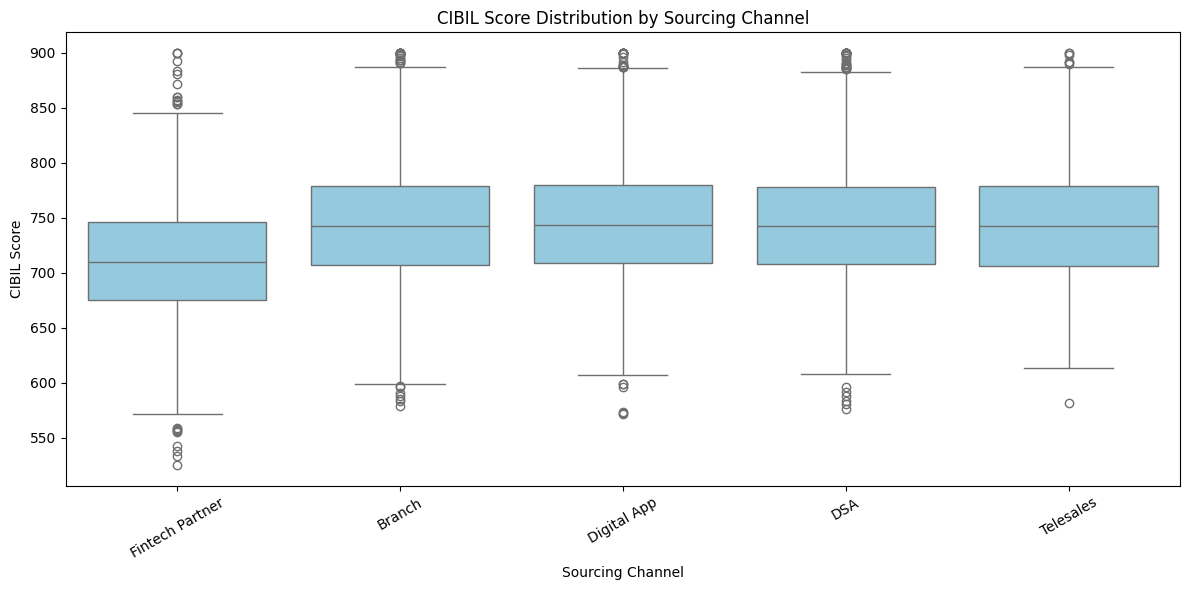

Interpretation: Lower median CIBIL scores may indicate that a channel serves customers with weaker credit profiles.


In [ ]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_d4[df_d4["valid_cibil"].notna()],
    x="sourcing_channel",
    y="valid_cibil",
    color="skyblue"
)

plt.title("CIBIL Score Distribution by Sourcing Channel")
plt.xlabel("Sourcing Channel")
plt.ylabel("CIBIL Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(
    "Interpretation: Lower median CIBIL scores may indicate "
    "that a channel serves customers with weaker credit profiles."
)


In [ ]:

# Create CIBIL score groups
cibil_bins = [299, 600, 650, 700, 750, 800, 900]

cibil_labels = [
    "300-599",
    "600-649",
    "650-699",
    "700-749",
    "750-799",
    "800-900"
]

df_d4["cibil_group"] = pd.cut(
    df_d4["cibil_score"],
    bins=cibil_bins,
    labels=cibil_labels
).astype("object")

# Keep customers with no credit history separate
df_d4.loc[
    df_d4["cibil_score"] == -1,
    "cibil_group"
] = "No Credit History"

# Exclude missing/invalid scores for this comparison
df_d4_cibil = df_d4[
    df_d4["cibil_group"].notna()
].copy()

cibil_channel_summary = (
    df_d4_cibil.groupby(
        ["cibil_group", "sourcing_channel"]
    )
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum")
    )
    .reset_index()
)

cibil_channel_summary["Bad_Loan_Rate_%"] = (
    cibil_channel_summary["Bad_Loans"] /
    cibil_channel_summary["Total_Loans"] * 100
).round(2)

display(
    cibil_channel_summary.sort_values(
        ["cibil_group", "Bad_Loan_Rate_%"],
        ascending=[True, False]
    )
)


,cibil_group,sourcing_channel,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
3,300-599,Fintech Partner,34,14,41.18
2,300-599,Digital App,6,2,33.33
1,300-599,DSA,6,1,16.67
0,300-599,Branch,8,1,12.50
4,300-599,Telesales,1,0,0.00
8,600-649,Fintech Partner,209,57,27.27
9,600-649,Telesales,59,15,25.42
7,600-649,Digital App,134,32,23.88
6,600-649,DSA,135,26,19.26
5,600-649,Branch,228,37,16.23


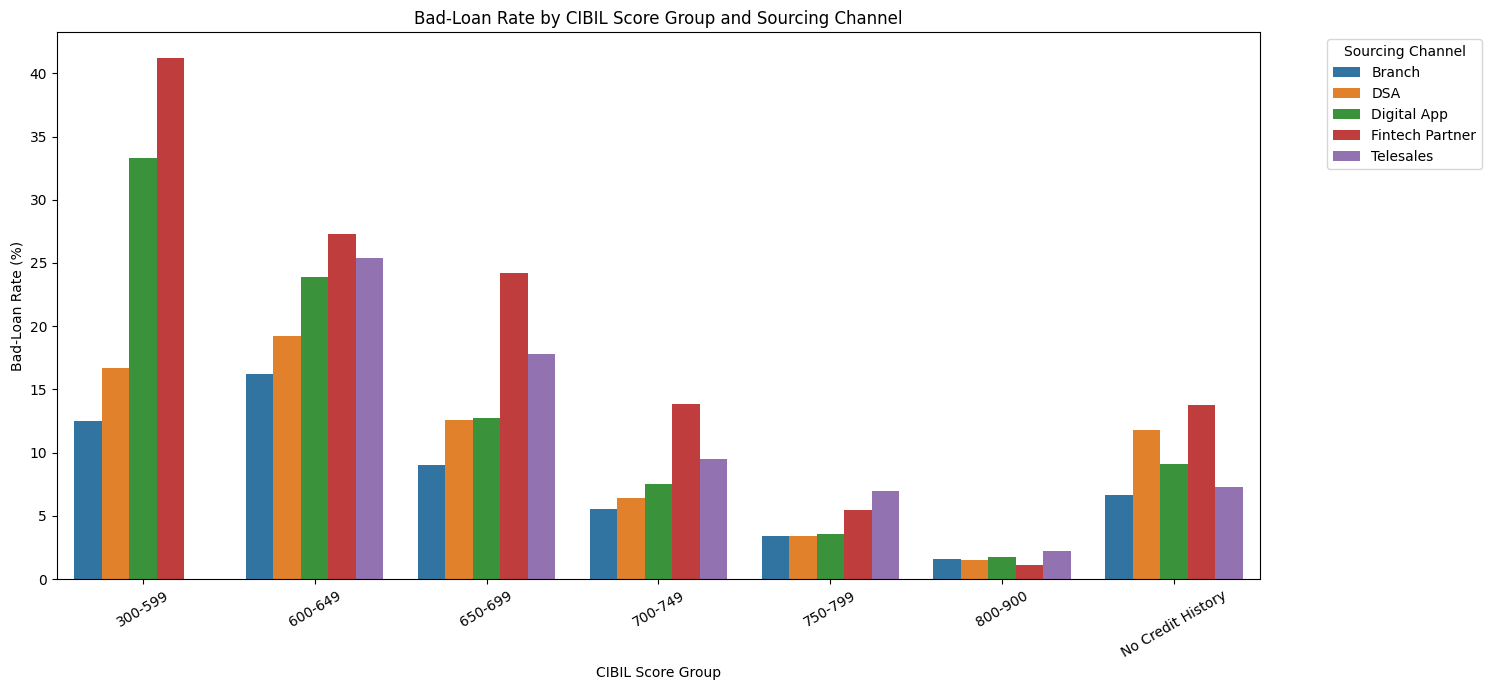

Interpretation: Compare channels within the same CIBIL group to see whether Fintech Partner retains higher bad-loan rates after accounting for credit score.


In [ ]:

plt.figure(figsize=(15, 7))

sns.barplot(
    data=cibil_channel_summary,
    x="cibil_group",
    y="Bad_Loan_Rate_%",
    hue="sourcing_channel",
    order=cibil_labels + ["No Credit History"]
)

plt.title("Bad-Loan Rate by CIBIL Score Group and Sourcing Channel")
plt.xlabel("CIBIL Score Group")
plt.ylabel("Bad-Loan Rate (%)")
plt.xticks(rotation=30)
plt.legend(
    title="Sourcing Channel",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

print(
    "Interpretation: Compare channels within the same CIBIL "
    "group to see whether Fintech Partner retains higher "
    "bad-loan rates after accounting for credit score."
)


What i got to understand is that fintech prefer to give risky loans they have gave loan even to the customers with no credit history also , they even gave loans to younger population.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_d5 = df_risk.copy()

bad_statuses = ["Default", "Charged Off", "Auctioned"]

df_d5["is_bad_loan"] = (
    df_d5["loan_status"].str.strip().isin(bad_statuses)
).astype(int)

# Classify CIBIL scores
df_d5["credit_history_group"] = np.select(
    [
        df_d5["cibil_score"].eq(-1),
        df_d5["cibil_score"].between(300, 900)
    ],
    [
        "No Credit History",
        "Has Credit History"
    ],
    default="Missing/Invalid CIBIL"
)

# Calculate bad-loan rates
credit_history_summary = (
    df_d5.groupby("credit_history_group")
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum")
    )
)

credit_history_summary["Bad_Loan_Rate_%"] = (
    credit_history_summary["Bad_Loans"] /
    credit_history_summary["Total_Loans"] * 100
).round(2)

display(credit_history_summary)


,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
credit_history_group,,,
Has Credit History,24460,1751,7.16
Missing/Invalid CIBIL,28,4,14.29
No Credit History,2255,230,10.20


In [ ]:

# Define CIBIL score ranges
bins = [299, 600, 650, 700, 750, 800, 900]

labels = [
    "300-599",
    "600-649",
    "650-699",
    "700-749",
    "750-799",
    "800-900"
]

df_d5["cibil_category"] = pd.cut(
    df_d5["cibil_score"],
    bins=bins,
    labels=labels
).astype("object")

# Keep no-credit-history customers separate
df_d5.loc[
    df_d5["cibil_score"] == -1,
    "cibil_category"
] = "No Credit History"

df_d5["cibil_category"] = df_d5[
    "cibil_category"
].fillna("Missing/Invalid")

# Calculate bad-loan rates
cibil_risk_summary = (
    df_d5.groupby("cibil_category")
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum")
    )
    .reset_index()
)

cibil_risk_summary["Bad_Loan_Rate_%"] = (
    cibil_risk_summary["Bad_Loans"] /
    cibil_risk_summary["Total_Loans"] * 100
).round(2)

display(
    cibil_risk_summary.sort_values(
        "Bad_Loan_Rate_%",
        ascending=False
    )
)


,cibil_category,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
0,300-599,55,18,32.73
1,600-649,765,167,21.83
6,Missing/Invalid,28,4,14.29
2,650-699,4727,626,13.24
7,No Credit History,2255,230,10.20
3,700-749,8448,610,7.22
4,750-799,7187,276,3.84
5,800-900,3278,54,1.65


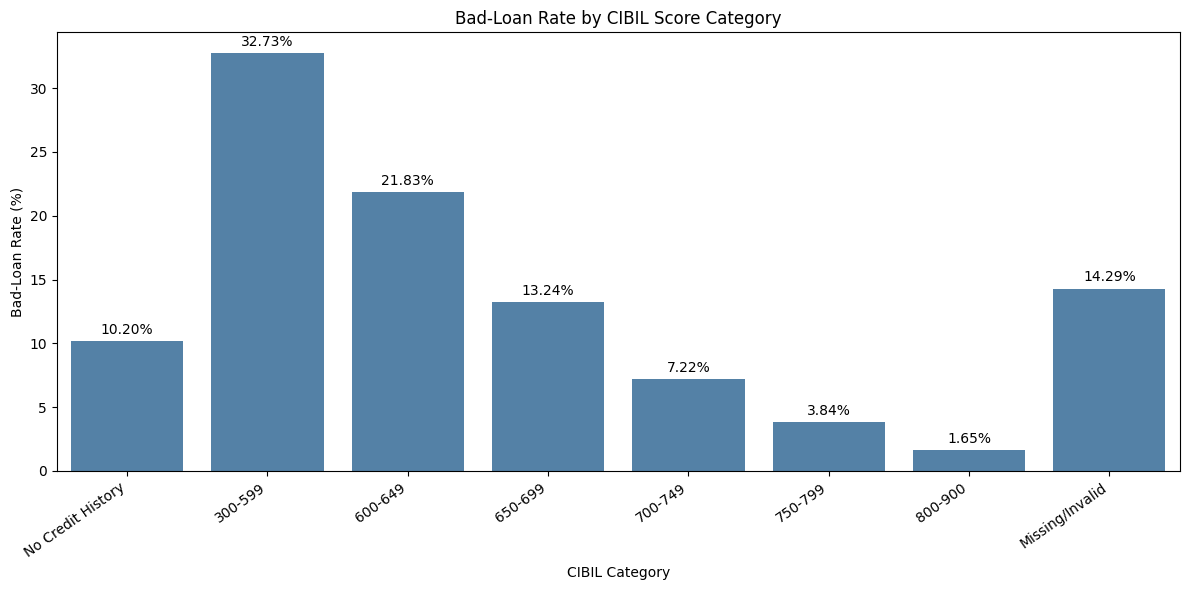

Interpretation: Compare customers with no credit history against low, medium, and high CIBIL score groups.


In [ ]:

# Order categories logically
category_order = [
    "No Credit History",
    "300-599",
    "600-649",
    "650-699",
    "700-749",
    "750-799",
    "800-900",
    "Missing/Invalid"
]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=cibil_risk_summary,
    x="cibil_category",
    y="Bad_Loan_Rate_%",
    order=category_order,
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Bad-Loan Rate by CIBIL Score Category")
plt.xlabel("CIBIL Category")
plt.ylabel("Bad-Loan Rate (%)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

print(
    "Interpretation: Compare customers with no credit history "
    "against low, medium, and high CIBIL score groups."
)


In [ ]:

# Exclude invalid CIBIL records
valid_groups = df_d5[
    df_d5["credit_history_group"].isin(
        ["No Credit History", "Has Credit History"]
    )
]

customer_comparison = (
    valid_groups.groupby("credit_history_group")
    .agg(
        Total_Loans=("loan_id", "count"),
        Average_Age=("age", "mean"),
        Median_Annual_Income=("annual_income", "median"),
        Median_Loan_Amount=("loan_amount", "median"),
        Average_Interest_Rate=("interest_rate", "mean"),
        Average_Existing_Loans=("num_existing_loans", "mean"),
        Bad_Loan_Rate=("is_bad_loan", "mean")
    )
)

customer_comparison["Bad_Loan_Rate"] *= 100

display(customer_comparison.round(2))


,Total_Loans,Average_Age,Median_Annual_Income,Median_Loan_Amount,Average_Interest_Rate,Average_Existing_Loans,Bad_Loan_Rate
credit_history_group,,,,,,,
Has Credit History,24460,34.62,715000.0,279000.0,11.73,1.7,7.16
No Credit History,2255,31.82,650500.0,218000.0,12.77,0.0,10.20


It is true that no credit history section can be risky but we can see that cibil score of 300-699 is more risky

,interest_group,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
0,0-5%,4064,196,4.82
1,5-10%,3142,61,1.94
2,10-15%,11889,864,7.27
3,15-20%,6403,756,11.81
4,20-25%,1185,100,8.44
5,25-30%,60,8,13.33
6,30%+,0,0,NaN


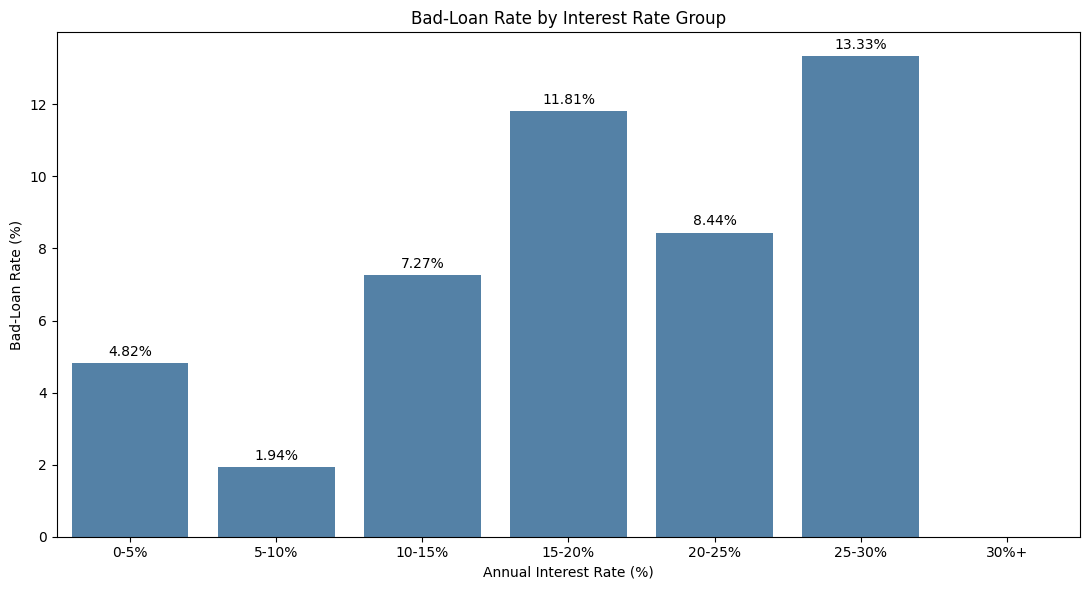

Interpretation: This chart compares observed bad-loan rates across interest-rate groups. Differences may also reflect underlying borrower risk and loan product.


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use older loans only (before 1 April 2024)
df_d6 = df_risk.copy()

# Define bad loans
bad_statuses = ["Default", "Charged Off", "Auctioned"]

df_d6["is_bad_loan"] = (
    df_d6["loan_status"].str.strip().isin(bad_statuses)
).astype(int)

# Create interest rate groups
bins = [-0.01, 5, 10, 15, 20, 25, 30, float("inf")]

labels = [
    "0-5%", "5-10%", "10-15%",
    "15-20%", "20-25%", "25-30%", "30%+"
]

df_d6["interest_group"] = pd.cut(
    df_d6["interest_rate"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate bad-loan rates
interest_summary = (
    df_d6.groupby("interest_group", observed=False)
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum")
    )
    .reset_index()
)

interest_summary["Bad_Loan_Rate_%"] = (
    interest_summary["Bad_Loans"] /
    interest_summary["Total_Loans"] * 100
).round(2)

display(interest_summary)

# Plot chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=interest_summary,
    x="interest_group",
    y="Bad_Loan_Rate_%",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Bad-Loan Rate by Interest Rate Group")
plt.xlabel("Annual Interest Rate (%)")
plt.ylabel("Bad-Loan Rate (%)")
plt.tight_layout()
plt.show()

print(
    "Interpretation: This chart compares observed bad-loan "
    "rates across interest-rate groups. Differences may also "
    "reflect underlying borrower risk and loan product."
)


I think interest rate plays the role but it is more the emi burden rate which is making default loans rate increase.

E1

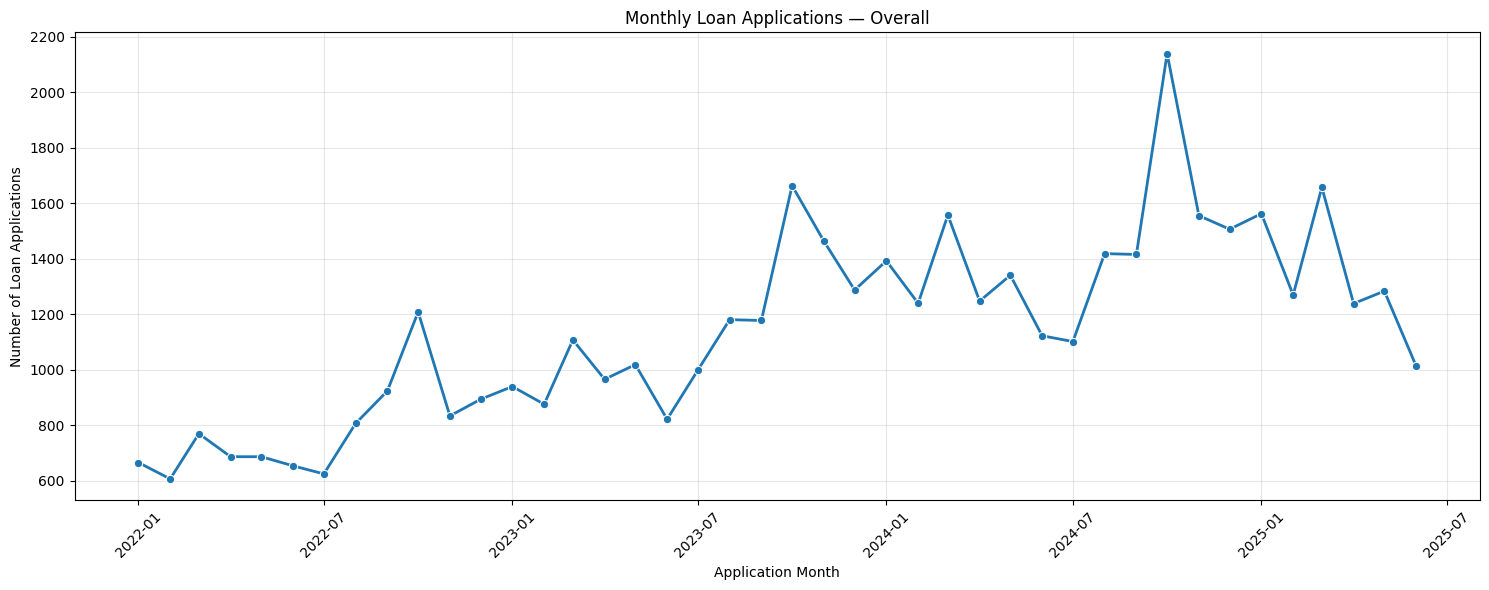

Interpretation: The chart shows how monthly loan application volumes change over time, including potential growth, declines and unusual spikes.


,application_month,Total_Applications
0,2022-01,666
1,2022-02,607
2,2022-03,770
3,2022-04,687
4,2022-05,687
5,2022-06,654
6,2022-07,625
7,2022-08,807
8,2022-09,924
9,2022-10,1209


In [61]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate dataframe
df_e1 = df.copy()

# Extract application month
df_e1["application_month"] = (
    df_e1["application_date"].dt.to_period("M")
)

# Count applications per month
monthly_applications = (
    df_e1.groupby("application_month")
    .agg(Total_Applications=("loan_id", "count"))
    .reset_index()
)

monthly_applications["month_date"] = (
    monthly_applications["application_month"].dt.to_timestamp()
)

# Plot overall trend
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_applications,
    x="month_date",
    y="Total_Applications",
    marker="o",
    linewidth=2
)

plt.title("Monthly Loan Applications — Overall")
plt.xlabel("Application Month")
plt.ylabel("Number of Loan Applications")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Interpretation: The chart shows how monthly loan "
    "application volumes change over time, including "
    "potential growth, declines and unusual spikes."
)

display(monthly_applications[
    ["application_month", "Total_Applications"]
])


Loans are mostly uncertain but if we see they are on increasing pattern , like the loans will increase with time.

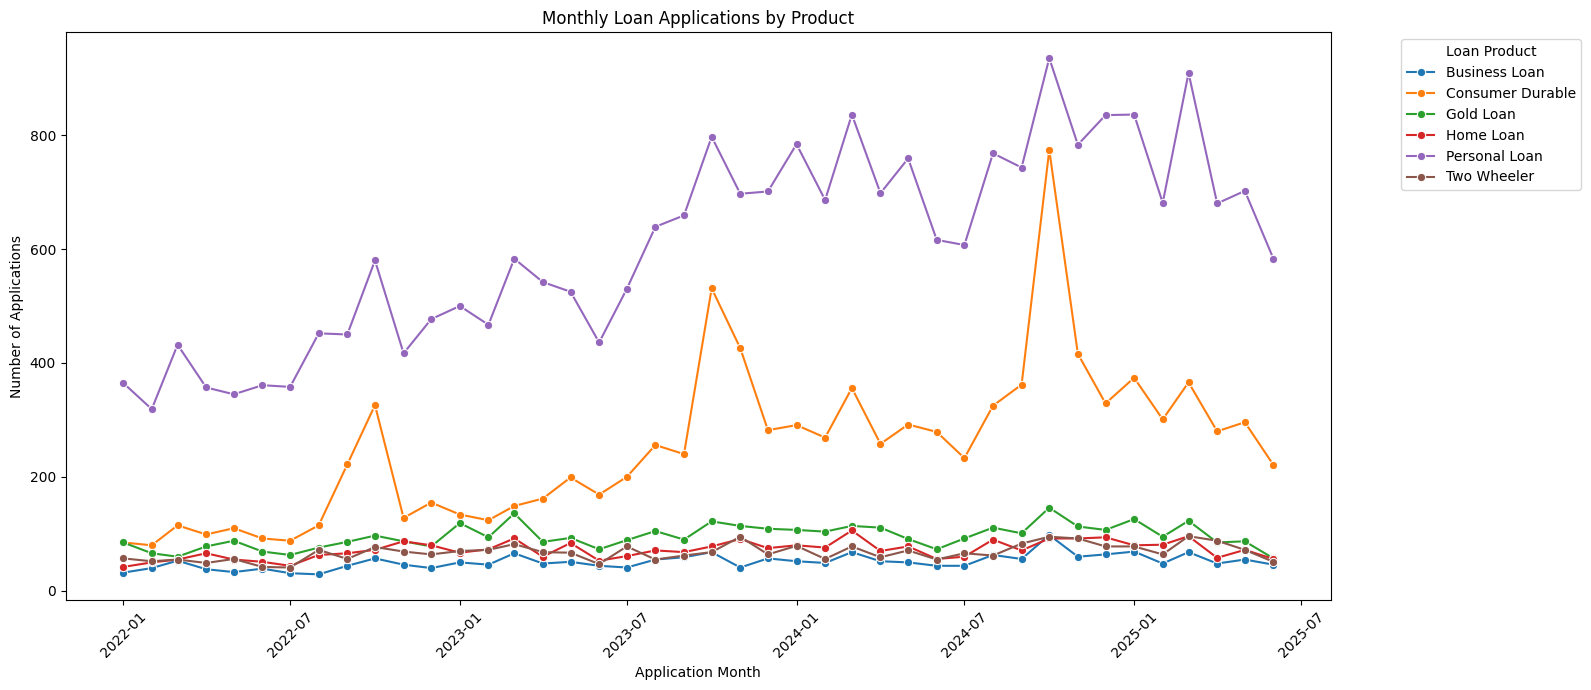

Interpretation: This chart compares monthly application trends across loan products to identify which products contribute to increases or decreases in total applications.


In [62]:

# Count applications per month and product
monthly_product = (
    df_e1.groupby(
        ["application_month", "product_type"]
    )
    .agg(Applications=("loan_id", "count"))
    .reset_index()
)

monthly_product["month_date"] = (
    monthly_product["application_month"].dt.to_timestamp()
)

plt.figure(figsize=(16, 7))

sns.lineplot(
    data=monthly_product,
    x="month_date",
    y="Applications",
    hue="product_type",
    marker="o"
)

plt.title("Monthly Loan Applications by Product")
plt.xlabel("Application Month")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45)
plt.legend(
    title="Loan Product",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

print(
    "Interpretation: This chart compares monthly application "
    "trends across loan products to identify which products "
    "contribute to increases or decreases in total applications."
)


I can see that the trend for personal loan , consumer loan is in spike , but the other loans are stagnant.

In [64]:

# Calculate average monthly applications
average_applications = (
    monthly_applications["Total_Applications"].mean()
)

# Identify months with applications > 120% of average
spike_threshold = average_applications * 1.20

spike_months = monthly_applications[
    monthly_applications["Total_Applications"] > spike_threshold
].copy()

print("Average monthly applications:",
      round(average_applications, 2))

print("Spike threshold (+20%):",
      round(spike_threshold, 2))

print("\nMonths with unusually high applications:")
display(
    spike_months[
        ["application_month", "Total_Applications"]
    ].sort_values("Total_Applications", ascending=False)
)


Average monthly applications: 1141.43
Spike threshold (+20%): 1369.71

Months with unusually high applications:


,application_month,Total_Applications
33,2024-10,2140
21,2023-10,1664
38,2025-03,1658
36,2025-01,1563
26,2024-03,1558
34,2024-11,1556
35,2024-12,1507
22,2023-11,1464
31,2024-08,1419
32,2024-09,1416


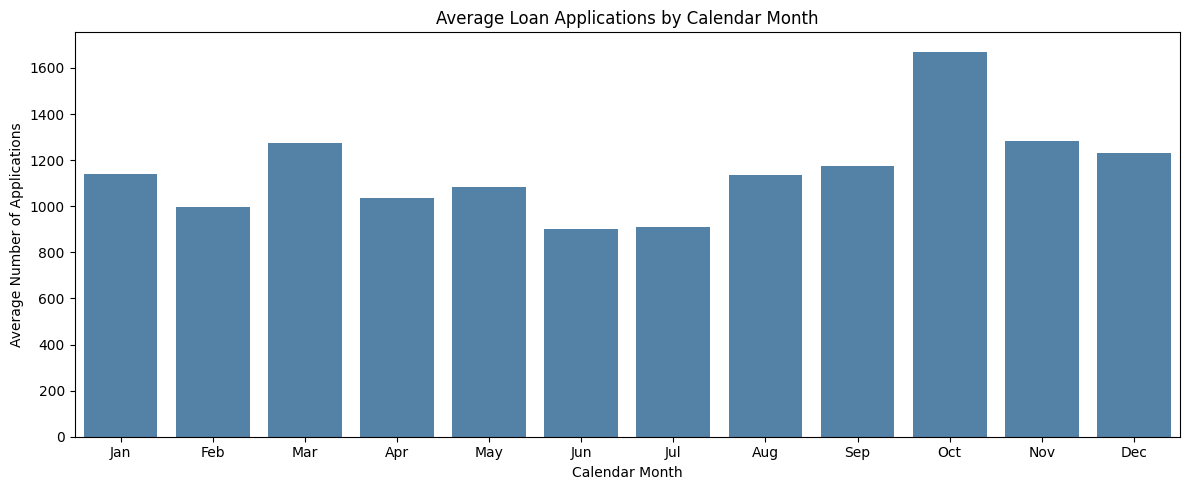

Interpretation: Repeated peaks in particular calendar months may indicate seasonal application patterns.


,calendar_month,Average_Applications,Month
0,1,1140.500000,Jan
1,2,998.250000,Feb
2,3,1273.500000,Mar
3,4,1035.000000,Apr
4,5,1082.750000,May
5,6,903.250000,Jun
6,7,908.666667,Jul
7,8,1135.666667,Aug
8,9,1172.666667,Sep
9,10,1671.000000,Oct


In [65]:

# Extract calendar month and year
monthly_applications["calendar_month"] = (
    monthly_applications["month_date"].dt.month
)

monthly_applications["year"] = (
    monthly_applications["month_date"].dt.year
)

# Average applications for each calendar month
seasonality = (
    monthly_applications.groupby("calendar_month")
    ["Total_Applications"]
    .mean()
    .reset_index(name="Average_Applications")
)

seasonality["Month"] = pd.to_datetime(
    seasonality["calendar_month"],
    format="%m"
).dt.strftime("%b")

plt.figure(figsize=(12, 5))

sns.barplot(
    data=seasonality,
    x="Month",
    y="Average_Applications",
    color="steelblue"
)

plt.title("Average Loan Applications by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Number of Applications")
plt.tight_layout()
plt.show()

print(
    "Interpretation: Repeated peaks in particular calendar "
    "months may indicate seasonal application patterns."
)

display(seasonality)


October has the highest demand may be due to fesitve season.

E2

In [66]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_e2 = df.copy()

# Extract weekday from application date
df_e2["day_of_week"] = df_e2["application_date"].dt.day_name()

# Correct weekday order
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Calculate application counts
weekday_channel = pd.crosstab(
    df_e2["day_of_week"],
    df_e2["sourcing_channel"]
).reindex(day_order, fill_value=0)

print("Application counts by weekday and sourcing channel:")
display(weekday_channel)

# Percentage distribution within each channel
weekday_percentage = (
    weekday_channel /
    weekday_channel.sum(axis=0) * 100
).round(2)

print("\nPercentage distribution within each channel:")
display(weekday_percentage)


Application counts by weekday and sourcing channel:


sourcing_channel,Branch,DSA,Digital App,Fintech Partner,Telesales
day_of_week,,,,,
Monday,3903,2744,1527,1052,1025
Tuesday,2296,1573,1562,1102,589
Wednesday,2088,1514,1482,1087,554
Thursday,2158,1553,1594,1076,567
Friday,2083,1547,1532,1041,545
Saturday,2242,1567,1505,1029,617
Sunday,335,204,1545,1030,72



Percentage distribution within each channel:


sourcing_channel,Branch,DSA,Digital App,Fintech Partner,Telesales
day_of_week,,,,,
Monday,25.84,25.64,14.21,14.18,25.83
Tuesday,15.20,14.70,14.53,14.86,14.84
Wednesday,13.82,14.15,13.79,14.66,13.96
Thursday,14.29,14.51,14.83,14.51,14.29
Friday,13.79,14.46,14.26,14.04,13.73
Saturday,14.84,14.64,14.00,13.87,15.55
Sunday,2.22,1.91,14.38,13.89,1.81


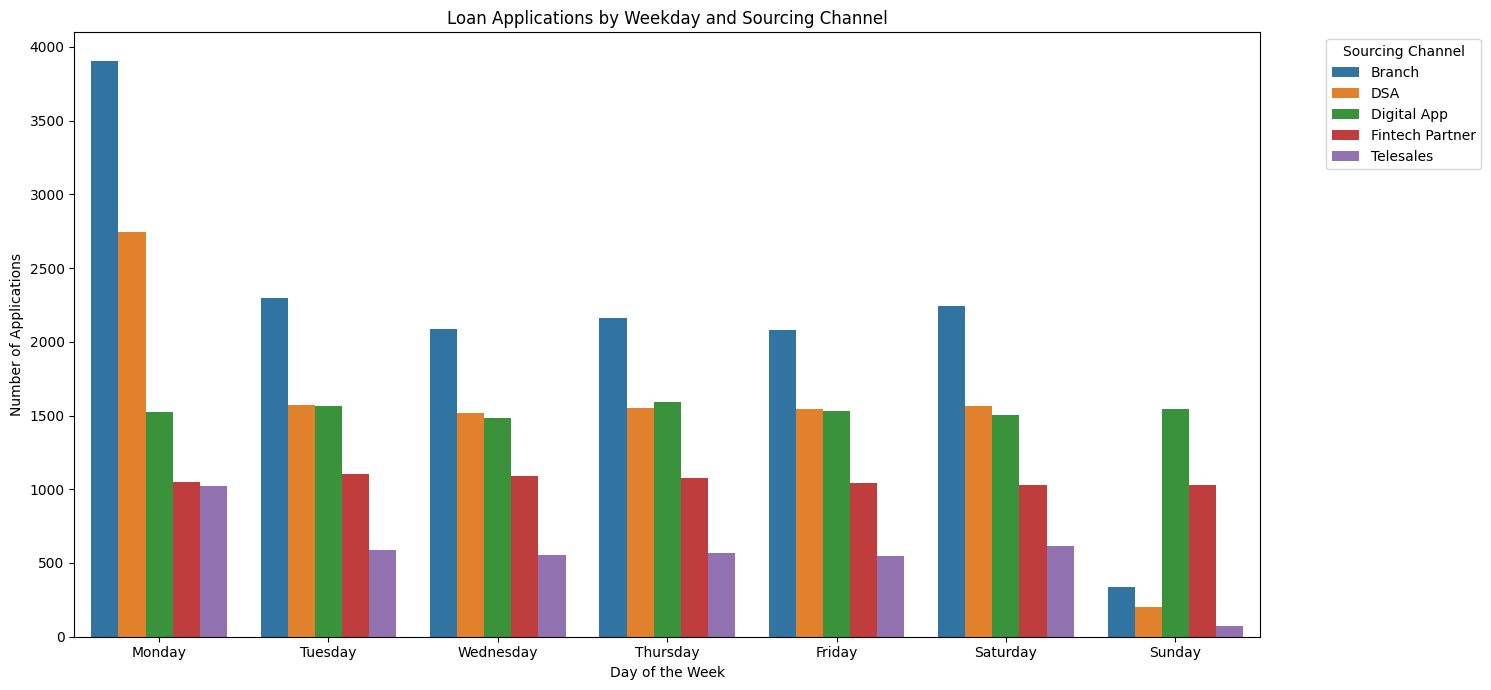

Interpretation: This chart compares weekday application volumes across sourcing channels and highlights differences between working days and weekends.


In [67]:

# Convert table to long format
plot_data = weekday_channel.reset_index().melt(
    id_vars="day_of_week",
    var_name="Sourcing Channel",
    value_name="Applications"
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=plot_data,
    x="day_of_week",
    y="Applications",
    hue="Sourcing Channel",
    order=day_order
)

plt.title("Loan Applications by Weekday and Sourcing Channel")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Applications")
plt.legend(
    title="Sourcing Channel",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

print(
    "Interpretation: This chart compares weekday application "
    "volumes across sourcing channels and highlights "
    "differences between working days and weekends."
)


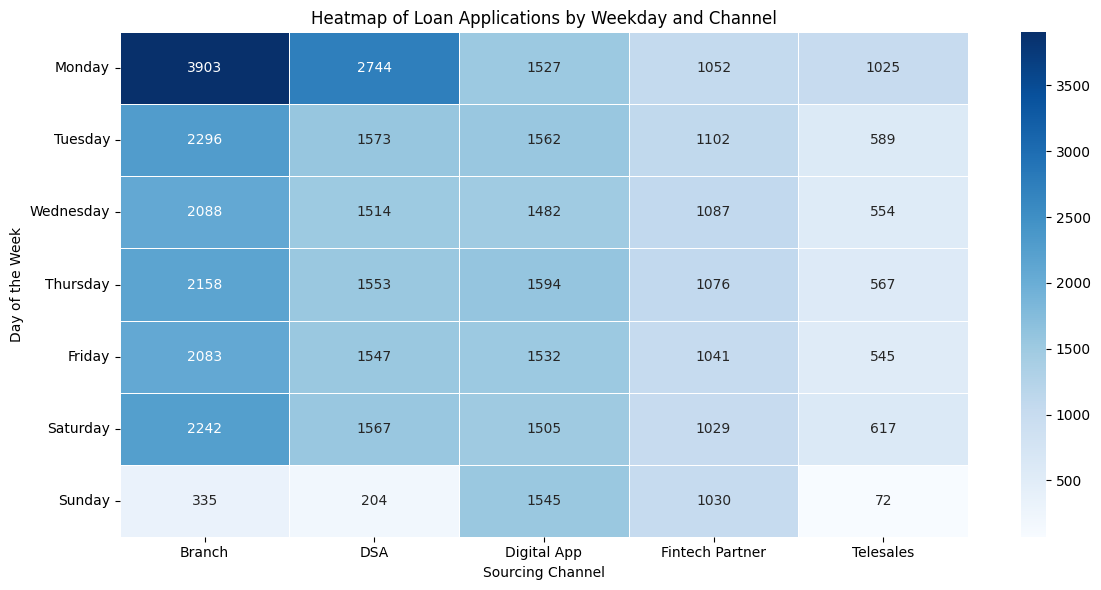

Interpretation: Darker cells represent higher application volumes, helping identify peak days for each channel.


In [68]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    weekday_channel,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Heatmap of Loan Applications by Weekday and Channel")
plt.xlabel("Sourcing Channel")
plt.ylabel("Day of the Week")
plt.tight_layout()
plt.show()

print(
    "Interpretation: Darker cells represent higher application "
    "volumes, helping identify peak days for each channel."
)


In [69]:

# Classify weekdays and weekends
df_e2["day_type"] = df_e2["day_of_week"].apply(
    lambda x: "Weekend" if x in ["Saturday", "Sunday"]
    else "Weekday"
)

weekend_summary = (
    df_e2.groupby(["sourcing_channel", "day_type"])
    .size()
    .unstack(fill_value=0)
)

weekend_summary["Total"] = weekend_summary.sum(axis=1)

weekend_summary["Weekend_%"] = (
    weekend_summary["Weekend"] /
    weekend_summary["Total"] * 100
).round(2)

weekend_summary["Weekday_%"] = (
    weekend_summary["Weekday"] /
    weekend_summary["Total"] * 100
).round(2)

display(
    weekend_summary.sort_values("Weekend_%", ascending=False)
)


day_type,Weekday,Weekend,Total,Weekend_%,Weekday_%
sourcing_channel,,,,,
Digital App,7697,3050,10747,28.38,71.62
Fintech Partner,5358,2059,7417,27.76,72.24
Telesales,3280,689,3969,17.36,82.64
Branch,12528,2577,15105,17.06,82.94
DSA,8931,1771,10702,16.55,83.45


Branch gets lot more customer for loans specially on monday the spike is more.

e3

In [70]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter loans disbursed before 1 April 2024
df_e3 = df[
    df["disbursal_date"] < pd.Timestamp("2024-04-01")
].copy()

# Define bad-loan statuses
bad_statuses = ["Default", "Charged Off", "Auctioned"]

df_e3["is_bad_loan"] = (
    df_e3["loan_status"].str.strip().isin(bad_statuses)
).astype(int)

# Extract disbursal quarter
df_e3["disbursal_quarter"] = (
    df_e3["disbursal_date"].dt.to_period("Q")
)

# Calculate quarterly bad-loan rates
quarterly_risk = (
    df_e3.groupby("disbursal_quarter")
    .agg(
        Total_Loans=("loan_id", "count"),
        Bad_Loans=("is_bad_loan", "sum")
    )
    .reset_index()
)

quarterly_risk["Bad_Loan_Rate_%"] = (
    quarterly_risk["Bad_Loans"] /
    quarterly_risk["Total_Loans"] * 100
).round(2)

display(quarterly_risk)


,disbursal_quarter,Total_Loans,Bad_Loans,Bad_Loan_Rate_%
0,2022Q1,1845,113,6.12
1,2022Q2,2056,124,6.03
2,2022Q3,2248,142,6.32
3,2022Q4,2964,182,6.14
4,2023Q1,2905,159,5.47
5,2023Q2,2893,207,7.16
6,2023Q3,3302,311,9.42
7,2023Q4,4430,364,8.22
8,2024Q1,4100,383,9.34


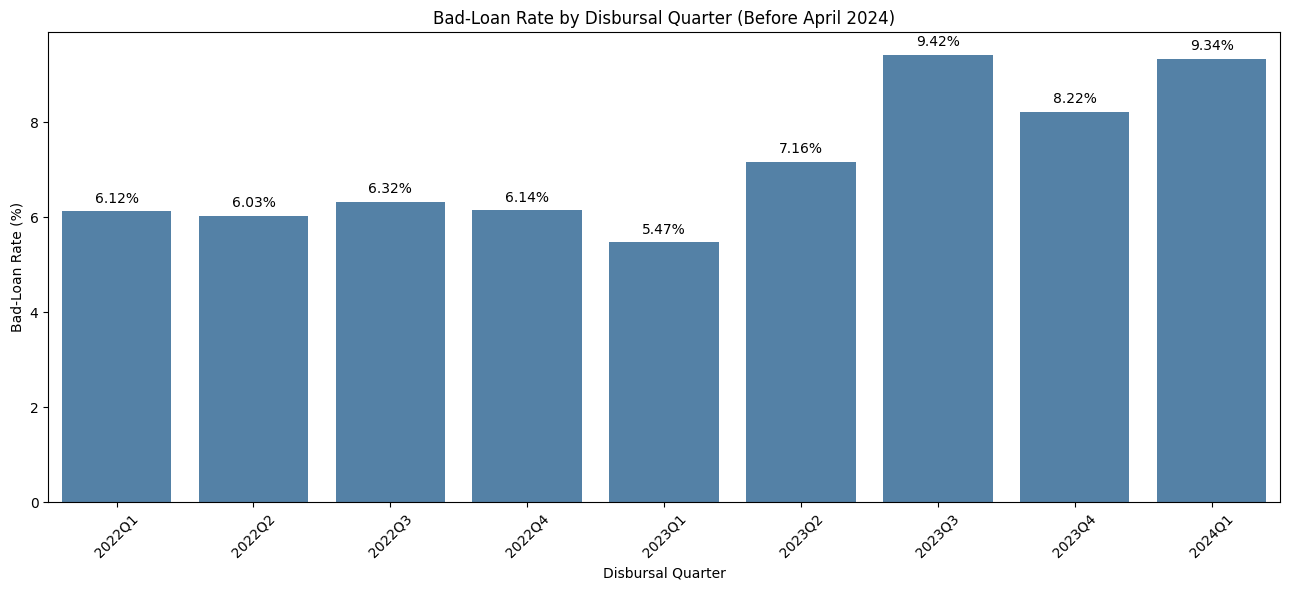

Interpretation: Higher bars indicate disbursal quarters with higher observed bad-loan rates among older loans.


In [71]:

quarterly_risk["Quarter_Label"] = (
    quarterly_risk["disbursal_quarter"].astype(str)
)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=quarterly_risk,
    x="Quarter_Label",
    y="Bad_Loan_Rate_%",
    color="steelblue"
)

# Display percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Bad-Loan Rate by Disbursal Quarter (Before April 2024)")
plt.xlabel("Disbursal Quarter")
plt.ylabel("Bad-Loan Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(
    "Interpretation: Higher bars indicate disbursal quarters "
    "with higher observed bad-loan rates among older loans."
)


The highest bad-loan rates were observed in Q3 2023 (9.42%) and Q1 2024 (9.34%).

One possible explanation is that some loans currently classified as bad may eventually recover through repayments or settlements. However, such recoveries do not necessarily mean that the original default classification was incorrect.

The elevated bad-loan rates could also reflect differences in borrower creditworthiness, loan products, sourcing channels, or lending policies during these periods.

Since the dataset represents loan statuses as of 30 September 2025, we cannot determine how these loans' statuses changed over time.

Therefore, further investigation is required before concluding why these quarters performed worse.